<!-- repro-header -->
> **Reproducibility header**
>
> - **Aim:** Multimodal RCC dataset: SOM (Spatiomic) communities and gene enrichment per community and uRNA category.
> - **Manuscript panels:** Fig. 4E-G, ED Fig. 6B
> - **Inputs:** RCC zarr with SOM communities (`rcc_som_multimodal_part2_batch/run_som_clustering.py`)
> - **Outputs:** Community maps, enrichment heatmaps
> - **Environment / kernel:** `troutpy_updated`
> - Data root: `/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy` (ROIs on Zenodo 10.5281/zenodo.17446348). 


# Aim of the notebook

This is how we run all datasets on a batch manner, except MERSCOPE ones. Those have their code in:
`processing_pipeline_MERSCOPE.ipynb`, same folder

# Load packages

In [1]:
import spatialdata as sd
#import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt
from spatialdata.transformations import get_transformation
import matplotlib.patches as patches
import os
import numpy as np
import sys
import spatiomic as so

import anndata as ad
import spatialdata as sd
import matplotlib.pyplot as plt
from tqdm import tqdm
import sys
import scipy.stats as stats
import numpy as np

In [2]:
import os
import pandas as pd
import numpy as np
import troutpy
import spatialdata as sd
from spatialdata import SpatialData

# --- SET YOUR PARAMETERS HERE ---
inpath = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc"  # Change this to your actual path
binsize = 3
background_filter = 0.4
gaussian_kernel_key = 2.0
sainsc_threads = 16
percentile_threshold = 10
square_size = 10
min_counts_env = 5
spatial_var_neighbors = 10
colocalization_threshold = 1
min_logfoldratio = 0.0
lambda_decay = 0.5
source_njobs = 10
max_p_val_noise=0.05
diffusion_params = {}
scatter_params = [
    ("mean_displacement", "extracellular_proportion", 1, 10, 0, 0),
    ("mean_displacement", "in_out_spearmanR", 1, 10, 0, 0),
]
spatial_map_categories = ["mean_displacement", "logfoldratio_over_noise",
    "in_out_spearmanR", "moran_I", "extracellular_proportion",
  "proportion_of_colocalized"]
spatial_map_top = 3
spatial_map_bottom = 3
spot_size_cells = 10
spot_size_extra = 15

# --- PIPELINE EXECUTION ---

# Prepare paths
figures_path = os.path.join(inpath, "figures")
os.makedirs(figures_path, exist_ok=True)
zarr_path = os.path.join(inpath, "data_with_source_score.zarr")
meta_path = os.path.join(inpath, "metadata.csv")

# Load data
sdata = sd.read_zarr(zarr_path) if hasattr(sd, "read_zarr") else SpatialData.read(zarr_path)
metadata = pd.read_csv(meta_path)


# Run troutpy workflow

In [3]:
import sys
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import scanpy as sc
import scipy.sparse as sp
from spatialdata.transformations import get_transformation
import spatialdata_io
from spatialdata.models import PointsModel

# --- CONFIGURE LOCAL DEVELOPER MODULE PATHS ---
# Local troutpy reproducibility path
from troutpy_reproducibility.batch_running import *

    
# Import local pipeline submodules directly
from troutpy import pl
from troutpy import tl
from troutpy import pp


Proportion of cells retained after filtering: 80.36%
Final adata shape: (41266, 405)


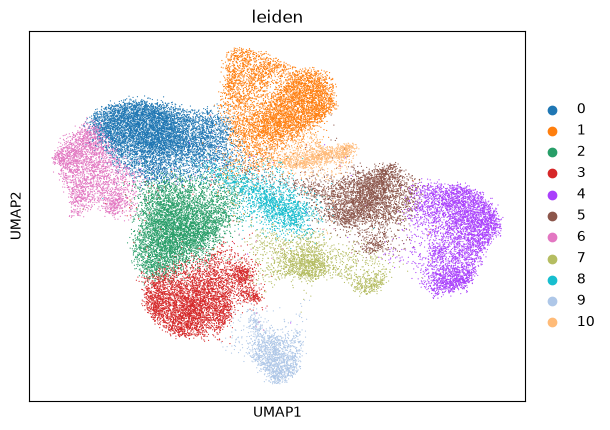

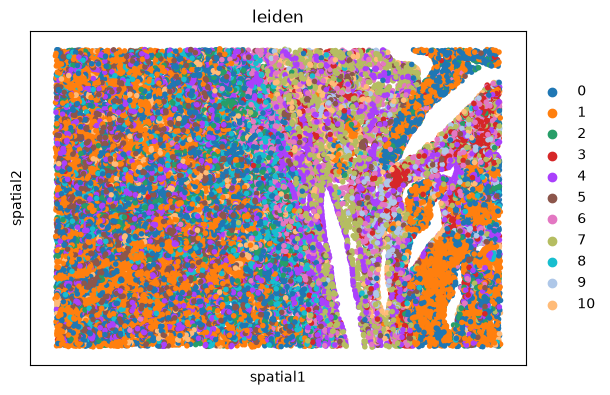

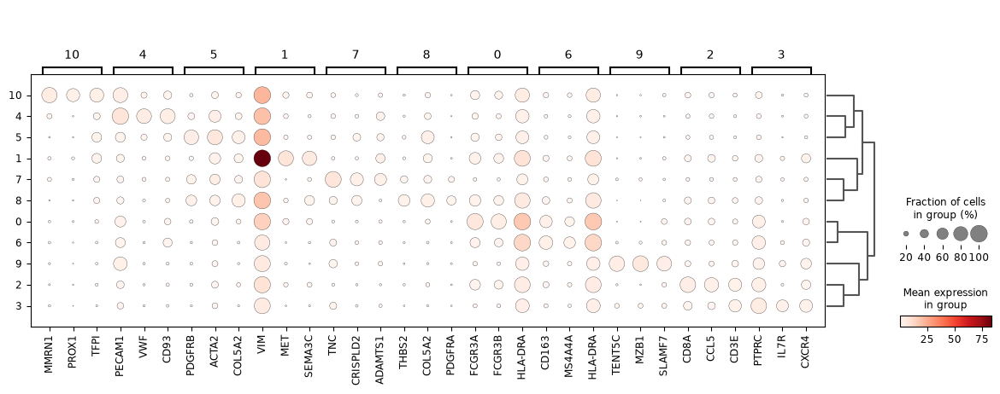

Identifying unique cells...
Loading transcripts for 500 cells...
Heuristic Radius from cell-subset: 1.5919
Calculating local counts for 7272244 transcripts...
Subsampling 500 cells to build likelihood distribution...
--- Analysis Complete ---
Expected Background Count: 1.78
Cell Model Median Count: 15.00


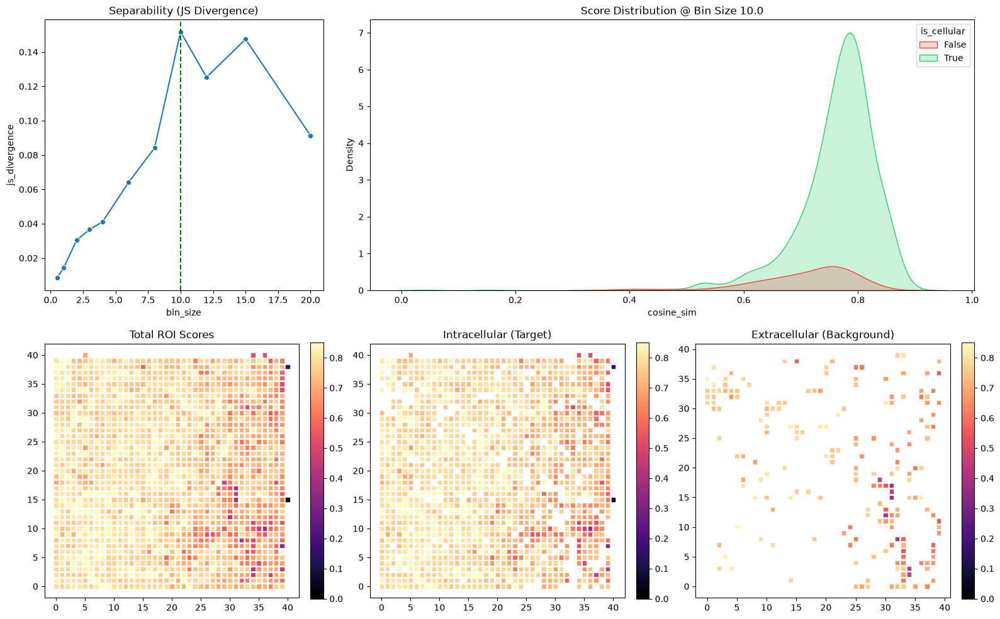

Text(0.5, 1.0, 'Cosine Similarity Distribution: Intra vs Extra-cellular')

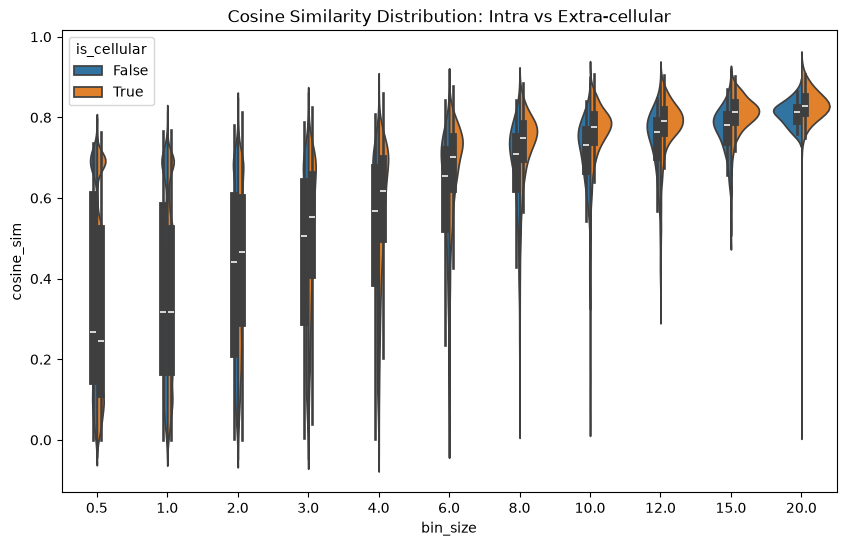

In [9]:
# --- METADATA & PLATFORM SPECIFIC PREPROCESSING ---
if 'metadata' in locals() and metadata is not None and len(metadata) > 0:
    # Technology-specific coordinate/identifier preprocessing
    if "technology" in metadata.columns:
        tech = metadata.loc[0, 'technology']
        
        if tech == 'CosMx':
            print("Applying platform-specific adjustments for CosMx data...")
            transcripts = sdata['transcripts'].compute().rename(columns={'cell_ID': 'cell_id'})
            transcripts['cell_id'] = transcripts['cell_id'].astype(str).replace(['0', '0.0'], 'UNASSIGNED')
            
            sdata['table'].obs = sdata['table'].obs.rename(columns={'cell_ID': 'cell_id'})
            sdata['table'].obs['cell_id'] = sdata['table'].obs['cell_id'].astype(str)
            sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)
            sdata['table'].uns['spatialdata_attrs']['instance_key'] = 'cell_id'
            
        elif tech == 'MERSCOPE':
            print("Applying platform-specific adjustments for MERSCOPE data...")
            transcripts = sdata['transcripts'].compute()
            transcripts['cell_id'] = transcripts['cell_id'].astype(str).replace(['-1'], 'UNASSIGNED')
            sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)
            sdata['table'].obs['cell_id'] = sdata['table'].obs['cell_id'].astype(str)
    
    # Segmentation fallback logic
    if "segmentation_method" in metadata.columns:
        if "nuclei" in str(metadata["segmentation_method"][0]):
            transcripts = sdata["transcripts"].compute()
            transcripts["overlaps_cell"] = transcripts["overlaps_nucleus"].astype(bool)
            sdata["transcripts"] = sd.models.PointsModel.parse(transcripts)
            print("Redefined overlaps_cell in transcripts using nuclei segmentation.")
else:
    print("No metadata found or loaded. Skipping preprocessing & fallback logic.")

# --- TRANSCRIPT CONTROL PROBE CLEANUP ---
tran = sdata['transcripts'].compute()
condition = tran['gene'].str.startswith('Unassigned', na=False)
tran['control_probe'] = np.where(condition, True, tran['control_probe'])
parsed_transcripts = PointsModel.parse(tran)
sdata['transcripts'] = parsed_transcripts

# --- PIPELINE EXECUTION ---
clustering_pipeline(sdata)
try:
    pp.add_morphological_metrics(sdata)
except Exception as e: 
    print(f"Warning: Morphological metrics calculation failed ({e}). Check data integrity.")

opt_r = tl.calculate_heuristic_radius_by_cells(sdata, k=10, n_cells=500)
tl.density_similarity(sdata, radius=opt_r, process_all=True, segmentation_key='overlaps_cell')

# Find optimal bin size using the preset parameters or fallback options
results, met_df, binsize_selected = pp.find_optimal_segmentation_free_bin_size(
    sdata, bin_sizes=[0.5, 1, 2, 3, 4, 6, 8, 10, 12, 15, 20], roi_size=400
)

# Plotting Cosine Similarity
plt.figure(figsize=(10, 6))
sns.violinplot(data=results, x="bin_size", y="cosine_sim", hue="is_cellular", split=True)
plt.title("Cosine Similarity Distribution: Intra vs Extra-cellular")


Saved optimal bin size violin plot to: /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc/figures/cosine_similarity_distribution.png
Defined 436337 URNA transcripts using Bayesian P > 0.5


Extracting gene counts: 100%|██████████| 493/493 [00:00<00:00, 5682.51it/s]


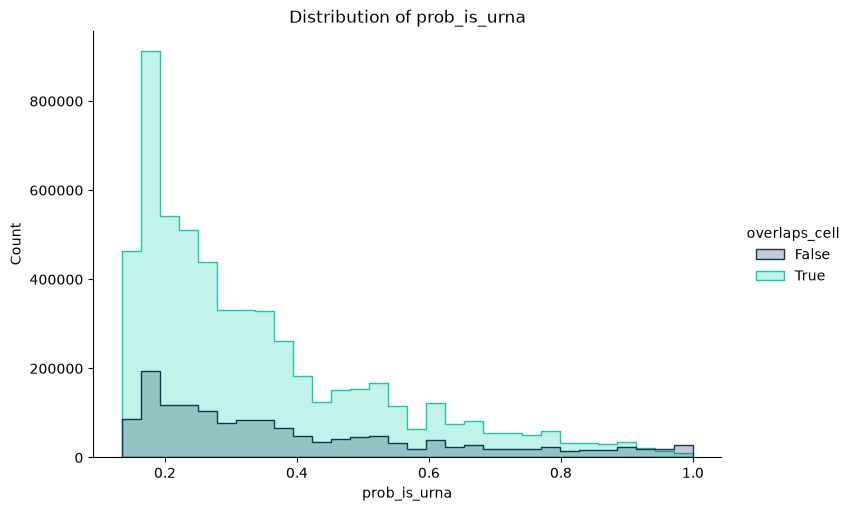

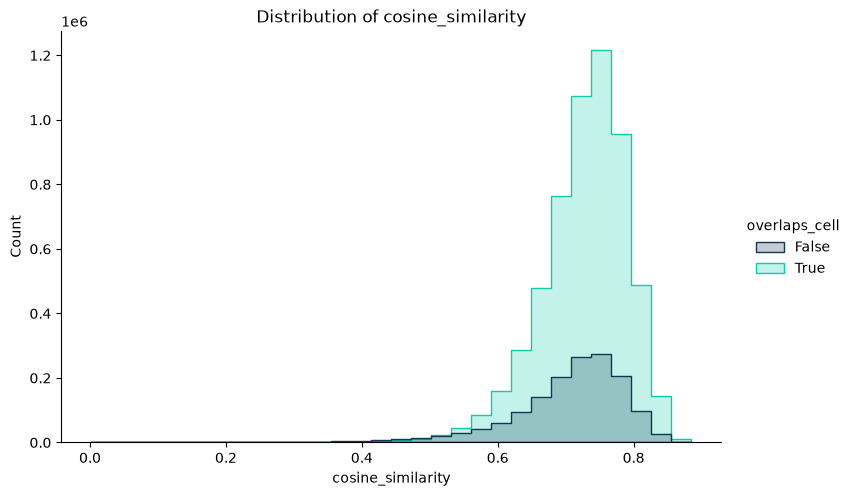

<Figure size 500x200 with 0 Axes>

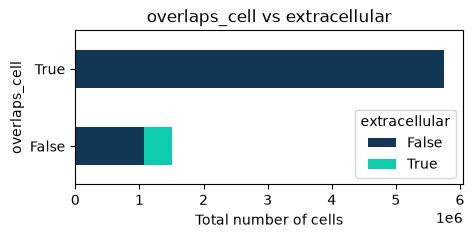

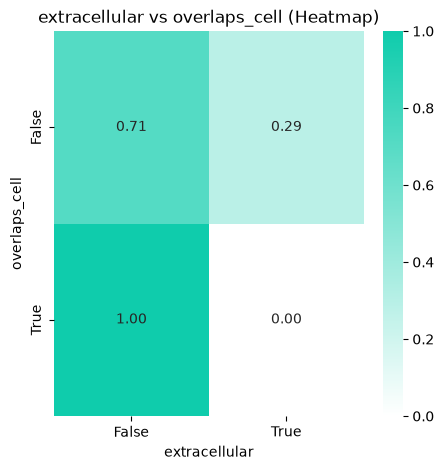

In [10]:
violin_out_path = os.path.join(figures_path, "cosine_similarity_distribution.png")
plt.savefig(violin_out_path, bbox_inches='tight', dpi=300)
plt.close()
print(f"Saved optimal bin size violin plot to: {violin_out_path}")

# Segmentation-free SAiNSC using variables from Cell 1
pp.segmentation_free_sainsc(
    sdata, binsize=binsize_selected, celltype_key="leiden", 
    background_filter=background_filter, gaussian_kernel_key=gaussian_kernel_key, 
    n_threads=sainsc_threads
)
pp.define_urna_probability(sdata)
pp.define_urna(sdata, method='sainsc')

# Histogram of scores
pl.histogram(sdata, x="prob_is_urna", hue="overlaps_cell", palette="troutpy", save=True, figures_path=figures_path)
pl.histogram(sdata, x="cosine_similarity", hue="overlaps_cell", palette="troutpy", save=True, figures_path=figures_path)

# Crosstabs and charts
pl.crosstab(
    sdata, yvar="extracellular", xvar="overlaps_cell", normalize=False, 
    cmap="troutpy", kind="barh", stacked=True, save=True, figures_path=figures_path, figsize=(5, 2)
)
pl.crosstab(
    sdata, xvar="extracellular", yvar="overlaps_cell", normalize=True, 
    cmap="Aquas", kind="heatmap", stacked=True, save=True, figures_path=figures_path
)

zarr_path_segfree = os.path.join(inpath, "data_with_segfree_2.zarr")
sdata.write(zarr_path_segfree, overwrite=True) 

# Single-value metrics computation
proportion_of_segmented = (sdata["transcripts"]["overlaps_cell"].compute() == True).sum() / len(sdata["transcripts"]["extracellular"].compute())
proportion_of_extracellular = (sdata["transcripts"]["extracellular"].compute() == True).sum() / len(sdata["transcripts"]["extracellular"].compute())

tl.quantify_overexpression(sdata, codeword_key="control_probe", control_codewords=[True])
tl.extracellular_enrichment(sdata, gene_key="gene")

# Aggregate extracellular metrics
pp.aggregate_urna(sdata, gene_key="gene", square_size=square_size)

# Environment Neighbor Estimation
nneighbors = estimate_environment_neighbors(
    sdata, cell_key="table", env_key="segmentation_free_table", min_counts=min_counts_env, plot=False
)

tl.spatial_variability(sdata, gene_key="gene", n_neighbors=spatial_var_neighbors, square_size=2 * square_size)
tl.in_out_correlation(sdata, n_neighbors=nneighbors)
tl.spatial_colocalization(sdata, threshold_colocalized=colocalization_threshold, copy=False)

sdata['xrna_metadata'].var['control_probe'] = ~sdata['xrna_metadata'].var['is_control']
sdata["xrna_metadata"].var["control_probe"] = sdata["xrna_metadata"].var["control_probe"].astype(bool)

# Calculate Noise & Gene Metadata profiles
gene_info = sdata["xrna_metadata"].var[sdata["xrna_metadata"].var['is_control'] == False]
genes_prop_over_noise = (gene_info['p_val_noise'] < max_p_val_noise).sum() / gene_info.shape[0]
non_noise_genes = gene_info[gene_info['p_val_noise'] < max_p_val_noise].index
all_gene_ids = sdata['transcripts']['gene'].compute()
noise_RNA_proportion = np.sum(all_gene_ids.isin(non_noise_genes)) / len(all_gene_ids)

# Save fully processed intermediate state
sdata.write(os.path.join(inpath, "data_processed_full.zarr"), overwrite=True)


In [11]:
# --- QUANTIFY STAININGS (WITH FALLBACK) ---
try:
    tl.image_intensities_per_transcript(
        sdata, image_key="morphology_focus", scale="scale0", 
        transcript_key="transcripts", extracellular=False, copy=False
    )
    pp.define_urna_probability_stainings(sdata)
except Exception as e:
    print("Not possible to define probabilities based on stainings.")

# Source score modelling optimization
min_enrichment = sdata.points['transcripts'][
    sdata.points['transcripts']['density_similarity_score'] > 0.5
]['enrichment_over_random'].min().compute()

tl.urna_source_score(
    sdata, chunk_size=100000, cell_type_col='leiden', max_dist=200, 
    lmbda=lambda_decay, max_k=10, ambient_floor=min_enrichment, 
    signal_threshold=10, residual=0.1, copy=False
)

try:
    table_name = "image_intensity_per_transcript"
    sdata.tables[table_name].obs['gene'] = (
        sdata.tables[table_name].obs['gene']
        .astype(str)
        .replace('nan', 'unknown') 
    )
except Exception as e:
    print("Could not process image intensity per transcript table for source score modelling.")

# Segment protrusions with adjusted parameters
tl.segment_protrusions(
    sdata, n_neighbors=10, cluster_eps=2.0, 
    connectivity_threshold=4.0, min_samples=1
)

# Assess diffusion
tl.assess_diffusion(
    sdata, gene_key="gene", distance_key="distance_to_source", 
    filters={'enrichment_class': ('High Density', False)}
)

# Output final modeled data matrix
sdata.write(os.path.join(inpath, "data_with_source_score.zarr"), overwrite=True)

# Calculate categories and generate final CSV stats
categories = pp.get_transcript_categories(sdata)

stats_df = pd.DataFrame({
    "Metric": [
        "proportion_of_segmented", 
        "proportion_of_extracellular", 
        "genes_prop_over_noise", 
        "noise_RNA_proportion"
    ],
    "Value": [
        proportion_of_segmented, 
        proportion_of_extracellular, 
        genes_prop_over_noise, 
        noise_RNA_proportion
    ]
})

stats_df.to_csv(os.path.join(figures_path, "pipeline_stats.csv"), index=False)
categories.to_csv(os.path.join(figures_path, "transcript_categories.csv"), index=False)
print(f"Pipeline completed smoothly. Figures and metrics saved in {figures_path}")

Calculating cosine similarities...
Calculating Bayesian distributions using 101725 background transcripts...
Probabilistic boundary (P=0.5) at similarity: 0.6072
Aligning data and cleaning IDs...
Building global spatial shell...
Building transcript spatial tree...
Processing 1731838 transcripts in 18 chunks...


100%|██████████| 18/18 [23:36<00:00, 78.72s/it]


Reconstructing results into AnnData...
Updating xrna_metadata and cell scores...
Success: 1731276 transcripts assigned.
--- Step 1: Extracting structures from 'transcripts' ---
--- Step 2: Computing morphology and metrics ---
--- Step 3: Assignment logic for 69110 structures ---


Analyzing Parents: 100%|██████████| 69110/69110 [01:02<00:00, 1111.03it/s]


--- Step 4: Updating sdata ---
Success! Registered 'structure_table' with morphological and parent metrics.
--- Diffusion Analysis Debug ---
Initial transcripts: 7272244
Transcripts passing filters: 6127346
Transcripts shared with source_score: 586940
SUCCESS: Statistics added for 387 genes.
Pipeline completed smoothly. Figures and metrics saved in /lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc/figures


# Read input sdata

In [4]:
inpath = "/lustre/groups/ml01/datasets/projects/2025_sergio_troutpy/rois/rois/xenium_rcc" 

In [5]:
zarr_path_segfree = os.path.join(inpath, "data_with_source_score.zarr")
sdata=sd.read_zarr(zarr_path_segfree) 

In [6]:
import anndata as ad
import spatialdata as sd
import matplotlib.pyplot as plt
from tqdm import tqdm
import sys
import scipy.stats as stats
import numpy as np

In [7]:
data=np.array(sdata['morphology_focus']['scale0'].image)
channels=np.array(sdata['morphology_focus']['scale0'].c)
# Reorder: 2nd becomes 1st (index 1), 3rd becomes 2nd (index 2), 1st becomes last (index 0)
data = data.transpose(1, 2, 0)


In [8]:
data=data[0:2000,0:2000,:]

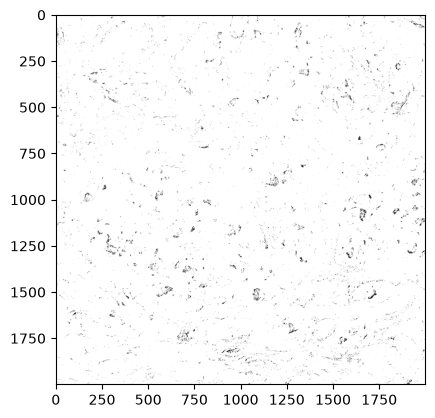

In [9]:
max_projection = data.max(axis=-1)
binary_mask = max_projection > 100
pixels_foreground = data[binary_mask,:]
plt.imshow(binary_mask, cmap="gray")

In [10]:

clipper = so.process.clip(percentile_min=1, percentile_max=99.9)
normalizer = so.process.normalize()
pixels_foreground_clipped = clipper.fit_transform(data)
pixels_foreground_normalized = normalizer.fit_transform(pixels_foreground_clipped)
subsample = so.data.subsample().fit_transform(pixels_foreground_normalized, method="count", count=100000, seed=0)
som = so.dimension.som(node_count=(20, 20),dimension_count=subsample.shape[1],seed=0)
som.fit(subsample, iteration_count=20)
knn_graph = so.neighbor.knn_graph().create(som, neighbor_count=10)
communities, modularity = so.cluster.leiden().predict(knn_graph, resolution=1.2)
communities = np.array(communities) + 1
# Flatten the labels to match the 1D shape of the masked array
labels = som.label(pixels_foreground_normalized, communities)
# flat
background_image = np.zeros_like(max_projection)
background_image[binary_mask] = labels[binary_mask].flatten()

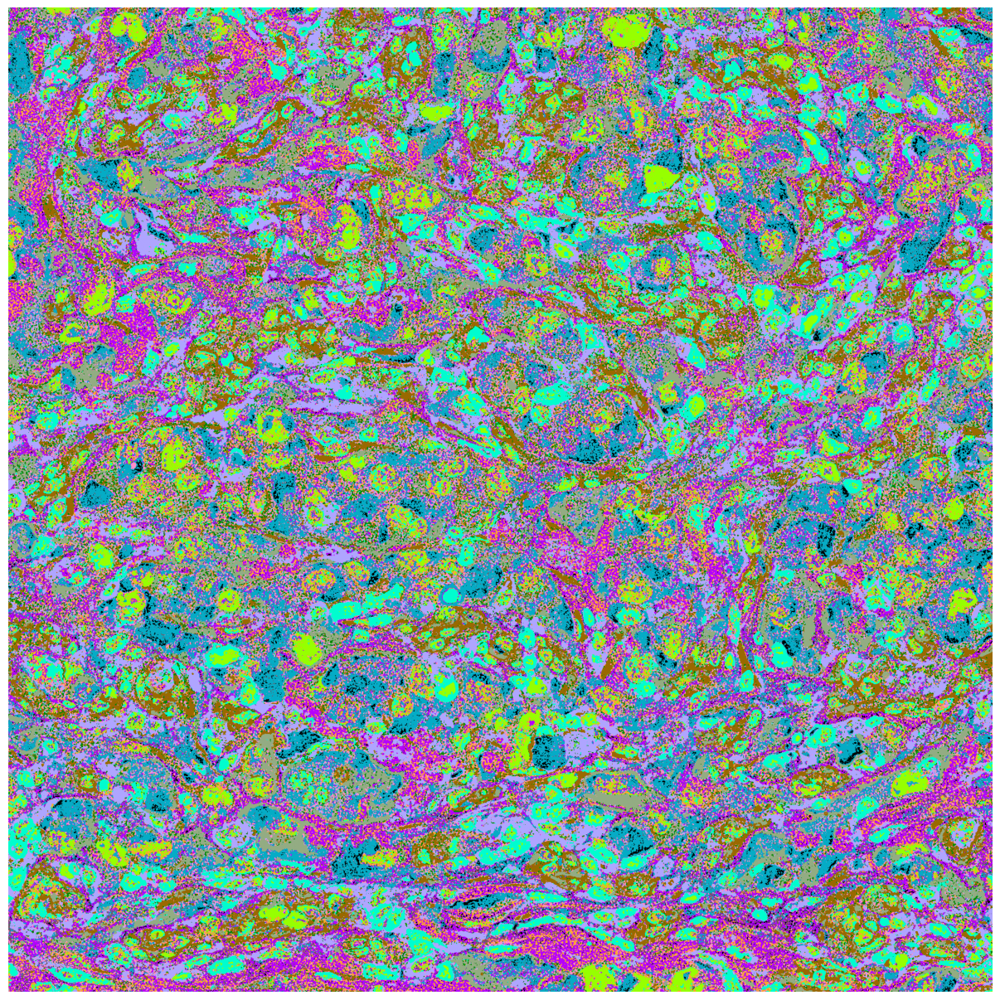

In [11]:
fig = so.plot.cluster_image(
    background_image,
    colormap=so.plot.colormap(
    color_count=len(np.unique(communities)) + 1,
    flavor="glasbey", color_override={0: "#000000"},
    ), figsize=(12, 12),show_colorbar=False)

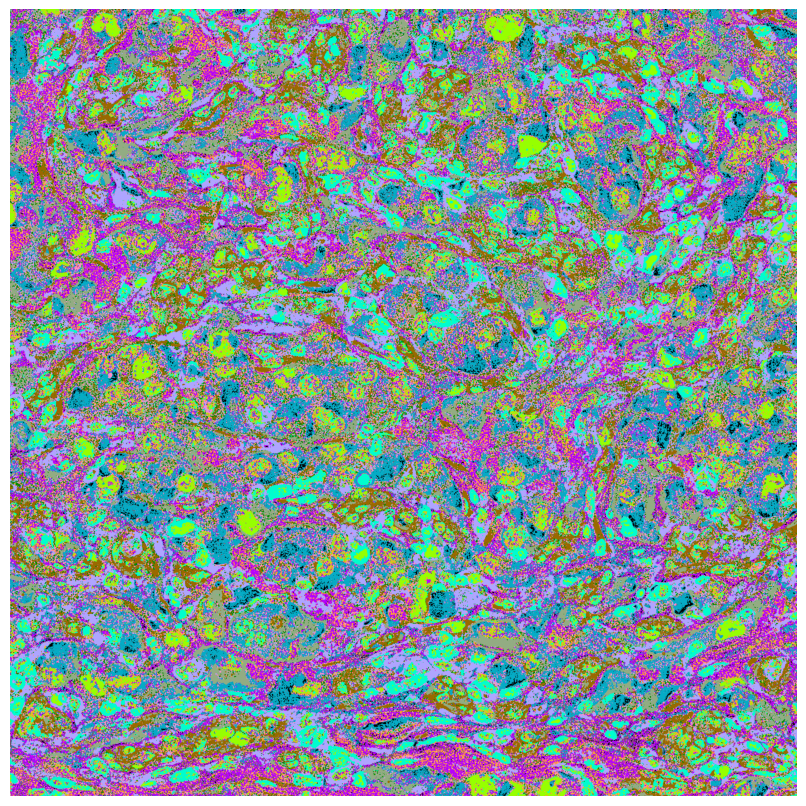

In [12]:
subset_image = background_image[0000:2000, 000:2000]

fig = so.plot.cluster_image(
    subset_image,colormap=so.plot.colormap(
    color_count=len(np.unique(communities)) + 1,
    flavor="glasbey", color_override={0: "#000000"},), 
    figsize=(8, 8),  show_colorbar=False)

In [13]:
# 1. Compute and subsample
transcripts = sdata.points["transcripts"].compute()
subsampled_df = transcripts.sample(frac=0.1, random_state=42)
# 2. Re-parse into a PointsModel and update the layer
sdata.points["transcripts"] = sd.models.PointsModel.parse(subsampled_df)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

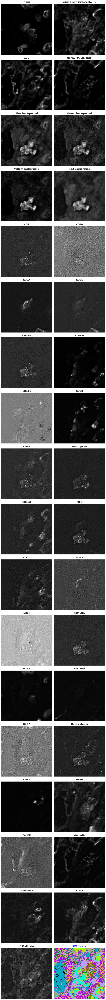

In [14]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the spatial subset (Zooming in)
y1, y2, x1, x2 = 00, 200, 0, 200

# 2. Get the number of channels
# Ensure 'channels' matches the 3rd dimension of 'data'
n_channels = data.shape[2]
n_total_plots = n_channels + 1 

# 3. Setup the Figure (Dynamic Grid)
cols = 2
rows = int(np.ceil(n_total_plots / cols))

fig, axes = plt.subplots(rows, cols, figsize=(cols * 4, rows * 4))
axes = axes.flatten()

# 4. Plot each channel with its specific name
for i in range(n_channels):
    subset_ch = data[y1:y2, x1:x2, i]
    
    # Use the channel name from your list
    ch_name = channels[i] if i < len(channels) else f"Channel {i}"
    
    axes[i].imshow(subset_ch, cmap='gray')
    axes[i].set_title(ch_name, fontsize=12, fontweight='bold')
    axes[i].axis('off')

# 5. Plot the SOM Cluster Map in the next available slot
cmap_so = so.plot.colormap(
    color_count=len(np.unique(communities)) + 1,
    flavor="glasbey", 
    color_override={0: "#000000"}
)

subset_clusters = background_image[y1:y2, x1:x2]
axes[n_channels].imshow(subset_clusters, cmap=cmap_so, interpolation='nearest')
axes[n_channels].set_title("SOM Clusters", fontsize=12, color='blue')
axes[n_channels].axis('off')

# 6. Hide any unused subplot axes
for j in range(n_total_plots, len(axes)):
    axes[j].axis('off')

plt.tight_layout()
plt.show()

In [15]:
import pandas as pd
import numpy as np
from tqdm import tqdm

def compute_community_means(data, background_image, channel_names):
    """
    Computes the mean intensity per channel for each SOM community.
    
    Parameters:
    - data: (Y, X, C) numpy array
    - background_image: (Y, X) numpy array with community IDs
    - channel_names: list of strings (C names)
    """
    # 1. Get unique community IDs (excluding 0 if it's background)
    unique_communities = np.unique(background_image)
    unique_communities = unique_communities[unique_communities != 0]
    
    # 2. Initialize a list to store results
    results = []

    # 3. Iterate through each community
    for community_id in tqdm(unique_communities, desc="Calculating mean intensities"):
        # Create a boolean mask for the current community
        mask = (background_image == community_id)
        
        # Extract pixels for this community across all channels
        # pixels shape will be (N_pixels_in_community, N_channels)
        community_pixels = data[mask]
        
        # Calculate mean for each channel
        means = np.mean(community_pixels, axis=0)
        
        # Store metadata + values
        res_row = {"community_id": int(community_id)}
        for i, ch_name in enumerate(channel_names):
            res_row[ch_name] = means[i]
            
        results.append(res_row)

    # 4. Create DataFrame
    df_means = pd.DataFrame(results).set_index("community_id")
    return df_means

# Usage
# 'channels' is your list of names, 'data' is your (Y, X, C) array
df_som_intensities = compute_community_means(data, background_image, channels)

# View the result
print(df_som_intensities.head())

Calculating mean intensities: 100%|██████████| 11/11 [00:00<00:00, 13.34it/s]

                    DAPI  ATP1A1/CD45/E-Cadherin        18S  \
community_id                                                  
1              27.407427               31.377763  37.770399   
2              13.972384               11.001808   7.989209   
3               5.793502                7.483744   7.219453   
4             171.267888               16.955194  13.222908   
5              60.445113               17.224781  18.720375   

              alphaSMA/Vimentin  Blue background  Green background  \
community_id                                                         
1                     28.072153        35.392415          3.436749   
2                      5.683291        25.019620          2.542676   
3                      7.267157        10.301865          1.331678   
4                      6.695063        50.836367          5.045439   
5                      8.785746        35.534664          3.798491   

              Yellow background  Red background        CD4       CD

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

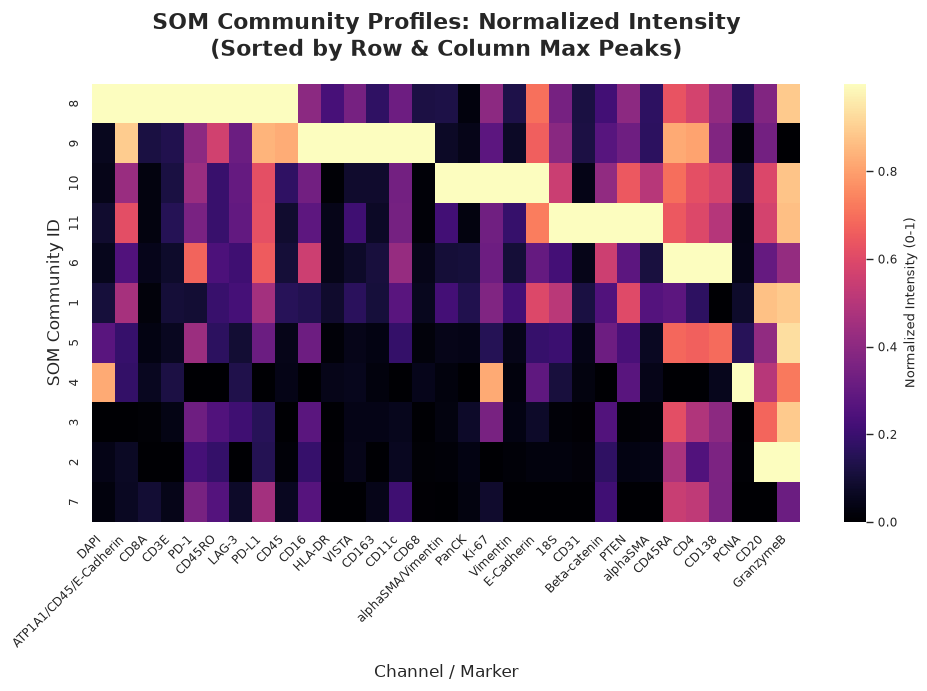

In [16]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_som_normalized_heatmap(df_means, figsize=(10, 7)):
    """
    Plots a heatmap of SOM communities using Min-Max normalization (0 to 1) per channel,
    excluding background channels, with rows sorted by mean community intensity and
    columns sorted by the row in which they reach their maximum intensity.
    """
    # 1. Exclude columns with 'background' in their name (case-insensitive)
    cols_to_keep = [col for col in df_means.columns if 'background' not in str(col).lower()]
    df_filtered = df_means[cols_to_keep]
    
    # 2. Min-Max Normalization (0 to 1 per channel)
    norm_df = (df_filtered - df_filtered.min()) / (df_filtered.max() - df_filtered.min() + 1e-8)
    
    # 3. Sort Communities (Rows) by Mean Intensity
    norm_df['row_mean'] = norm_df.mean(axis=1)
    norm_df = norm_df.sort_values(by='row_mean', ascending=False)
    plot_df = norm_df.drop(columns=['row_mean'])

    # 4. Sort Columns (Channels) by the row position of their peak (max) intensity
    # Map row index labels to their integer row positions (0 to N-1)
    row_pos_map = {row_label: pos for pos, row_label in enumerate(plot_df.index)}
    
    # Find position of maximum value for each column
    col_peak_positions = plot_df.idxmax(axis=0).map(row_pos_map)
    
    # Sort columns by peak row position
    sorted_cols = col_peak_positions.sort_values(ascending=True).index
    plot_df = plot_df[sorted_cols]

    # 5. Setup Visuals
    plt.figure(figsize=figsize)
    
    sns.heatmap(
        plot_df, 
        cmap="magma", 
        robust=True, 
        cbar_kws={'label': 'Normalized Intensity (0-1)'},
        linewidths=0,
        xticklabels=True, 
        yticklabels=True
    )

    # 6. Styling
    plt.title("SOM Community Profiles: Normalized Intensity\n(Sorted by Row & Column Max Peaks)", 
              fontsize=16, fontweight='bold', pad=20)
    plt.xlabel("Channel / Marker", fontsize=12, labelpad=10)
    plt.ylabel("SOM Community ID", fontsize=12)
    
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

plot_som_normalized_heatmap(df_som_intensities)

findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font family 'Arial' not found.
findfont: Font f

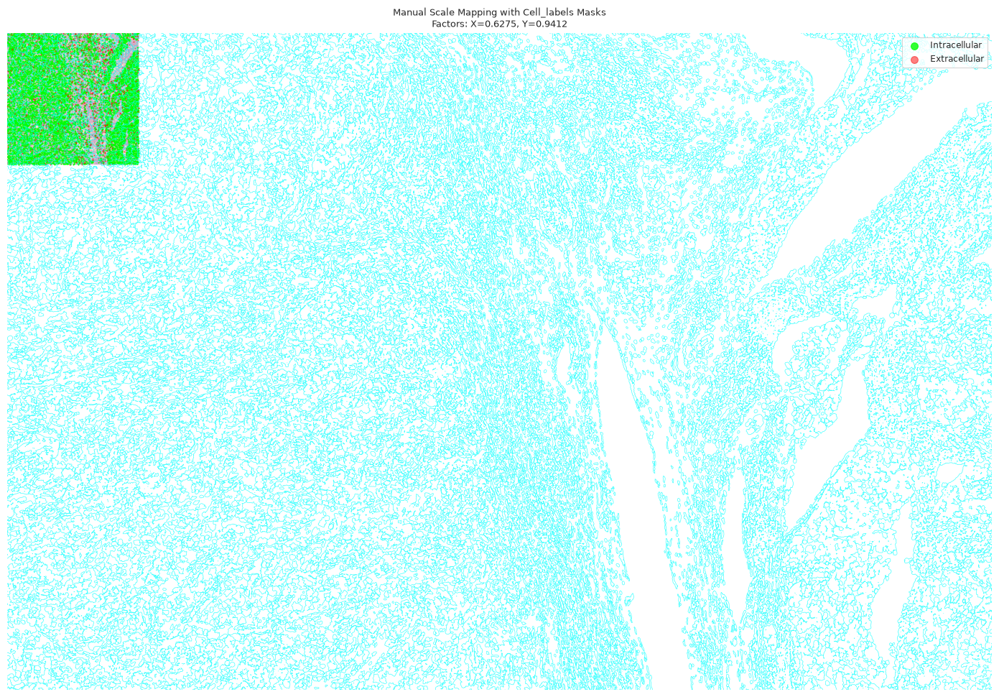

In [17]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

def visualize_manual_scaling_alignment(sdata, background_image, n_samples=15000, plot_masks=True, mask_type="cell_labels"):
    # 1. Load transcripts
    df_tx = sdata.points["transcripts"].compute()
    
    # 2. Calculate the "Envelope" (Min/Max of Transcripts)
    minx, maxx = df_tx.x.min(), df_tx.x.max()
    miny, maxy = df_tx.y.min(), df_tx.y.max()
    
    tx_width = maxx - minx
    tx_height = maxy - miny
    
    # 3. Get Image Dimensions
    img_h, img_w = background_image.shape
    
    # 4. Calculate Scaling Factors (Pixels per Physical Unit)
    mf_x = img_w / tx_width
    mf_y = img_h / tx_height
    
    # 5. Apply Transformation: (Global - Min) * Factor
    df_tx["x_scaled"] = (df_tx["x"] - minx) * mf_x
    df_tx["y_scaled"] = (df_tx["y"] - miny) * mf_y
    
    # 6. Plotting
    df_sub = df_tx.sample(n=min(n_samples, len(df_tx)))
    
    plt.figure(figsize=(14, 14))
    
    # Layer 1: Background Image
    plt.imshow(background_image, cmap='magma', alpha=0.4)
    
    # Layer 2: Cell / Nucleus Segmentation Masks
    if plot_masks and mask_type in sdata.labels:
        # Extract highest resolution scale (scale0) as a 2D numpy array
        labels_tree = sdata.labels[mask_type]
        # Access the scale0 image array
        mask_array = labels_tree["scale0"][list(labels_tree["scale0"].data_vars)[0]].compute().values
        
        # Binary mask representing cell/nucleus regions (> 0)
        binary_mask = mask_array > 0
        
        # Option A: Plot cell boundaries/contours (recommended for clean overlay)
        plt.contour(binary_mask, levels=[0.5], colors='cyan', linewidths=0.5, alpha=0.7)
        
        # Option B: Uncomment if you prefer filled semi-transparent cell masks instead:
        # mask_visual = np.ma.masked_where(~binary_mask, binary_mask)
        # plt.imshow(mask_visual, cmap='Blues', alpha=0.3)

    # Layer 3: Transcripts Overlay
    intra = df_sub[df_sub['extracellular'] == False]
    extra = df_sub[df_sub['extracellular'] == True]
    
    plt.scatter(intra['x_scaled'], intra['y_scaled'], s=0.5, c='lime', label='Intracellular', alpha=0.8)
    plt.scatter(extra['x_scaled'], extra['y_scaled'], s=0.5, c='red', label='Extracellular', alpha=0.5)
    
    plt.title(f"Manual Scale Mapping with {mask_type.capitalize()} Masks\nFactors: X={mf_x:.4f}, Y={mf_y:.4f}")
    plt.legend(markerscale=10, loc='upper right')
    plt.axis('off')
    plt.tight_layout()
    plt.show()
    
    return mf_x, mf_y, minx, miny

# Run Visualization
mfx, mfy, mx, my = visualize_manual_scaling_alignment(
    sdata, 
    background_image, 
    plot_masks=True, 
    mask_type="cell_labels" # or "nucleus_labels"
)

# Community mapping

For each transcript, we calculate which community it belongs to 

In [20]:
import numpy as np
import pandas as pd
from scipy.ndimage import map_coordinates

def assign_som_community_to_transcripts(sdata, background_image):
    """
    Assigns each transcript in sdata to a SOM community based on spatial 
    overlap with the background SOM image.
    
    Parameters:
    -----------
    sdata : SpatialData
        The SpatialData object containing the 'transcripts' points.
    background_image : np.ndarray
        2D array where each pixel value corresponds to a SOM Community ID.
        
    Returns:
    --------
    df_tx : pd.DataFrame
        DataFrame of transcripts containing new columns:
        'x_scaled', 'y_scaled', and 'som_community'.
    """
    # 1. Compute/Load transcript points
    df_tx = sdata.points["transcripts"].compute()
    
    # 2. Get bounding box coordinates (Envelope)
    minx, maxx = df_tx["x"].min(), df_tx["x"].max()
    miny, maxy = df_tx["y"].min(), df_tx["y"].max()
    
    tx_width = maxx - minx
    tx_height = maxy - miny
    
    # 3. Get Image Dimensions (Height = Y rows, Width = X columns)
    img_h, img_w = background_image.shape
    
    # 4. Calculate Scaling Factors (Pixels per Physical Unit)
    mf_x = img_w / tx_width
    mf_y = img_h / tx_height
    
    # 5. Transform Global Coordinates to Pixel Coordinates
    df_tx["x_scaled"] = (df_tx["x"] - minx) * mf_x
    df_tx["y_scaled"] = (df_tx["y"] - miny) * mf_y
    
    # 6. Clip coordinates to prevent index out-of-bounds errors at boundaries
    # Clip X to [0, img_w - 1] and Y to [0, img_h - 1]
    y_coords = np.clip(df_tx["y_scaled"].values, 0, img_h - 1)
    x_coords = np.clip(df_tx["x_scaled"].values, 0, img_w - 1)
    
    # 7. Spatial Lookup: Map (Y, X) coordinates to pixel values in background_image
    # order=0 uses nearest-neighbor interpolation to preserve categorical Community IDs
    som_assignments = map_coordinates(
        background_image, 
        [y_coords, x_coords], 
        order=0, 
        mode='nearest'
    )
    
    # 8. Assign assigned SOM Community IDs back to the DataFrame
    df_tx["som_community"] = som_assignments
    
    return df_tx

# Usage:
df_assigned = assign_som_community_to_transcripts(sdata, background_image)

# Check the distribution of transcripts per SOM community
print(df_assigned["som_community"].value_counts())

som_community
3     101615
2      96972
9      88718
6      68661
5      66362
8      63845
10     58116
11     55112
1      46663
4      43415
7      28678
0       9067
Name: count, dtype: int64


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

def plot_som_transcript_alignment(df_assigned, background_image, n_samples=30000):
    """
    Plots the background SOM image alongside a sample of transcripts 
    colored by their assigned SOM community to verify spatial alignment.
    """
    # 1. Sample transcripts for fast rendering
    df_sub = df_assigned.sample(n=min(n_samples, len(df_assigned)), random_state=42)
    
    # 2. Get unique SOM communities and set up discrete color palette
    unique_soms = sorted(df_assigned["som_community"].unique())
    n_colors = len(unique_soms)
    palette = sns.color_palette("tab20", n_colors)
    color_map = dict(zip(unique_soms, palette))
    
    fig, axes = plt.subplots(1, 2, figsize=(20, 10), sharex=True, sharey=True)
    
    # Subplot 1: Original Background Image
    # (Uses categorical colormap matching unique IDs)
    im = axes[0].imshow(background_image, cmap='tab20', interpolation='nearest')
    axes[0].set_title("1. Original SOM Background Image", fontsize=14, fontweight='bold')
    axes[0].axis('off')
    
    # Subplot 2: Assigned Transcripts Scatter Plot
    point_colors = df_sub["som_community"].map(color_map)
    axes[1].scatter(
        df_sub["x_scaled"], 
        df_sub["y_scaled"], 
        c=point_colors, 
        s=0.3, 
        alpha=0.6
    )
    
    # Invert Y axis on scatter so origin (0,0) matches top-left image orientation
    axes[1].set_ylim(background_image.shape[0], 0)
    axes[1].set_xlim(0, background_image.shape[1])
    axes[1].set_title(f"2. Transcripts Colored by Assigned SOM (N={len(df_sub):,})", fontsize=14, fontweight='bold')
    axes[1].axis('off')
    
    plt.tight_layout()
    plt.show()

# Run the spatial verification plot
plot_som_transcript_alignment(df_assigned, background_image)

In [ ]:
# for each community, how much is intra vs extra and which types.

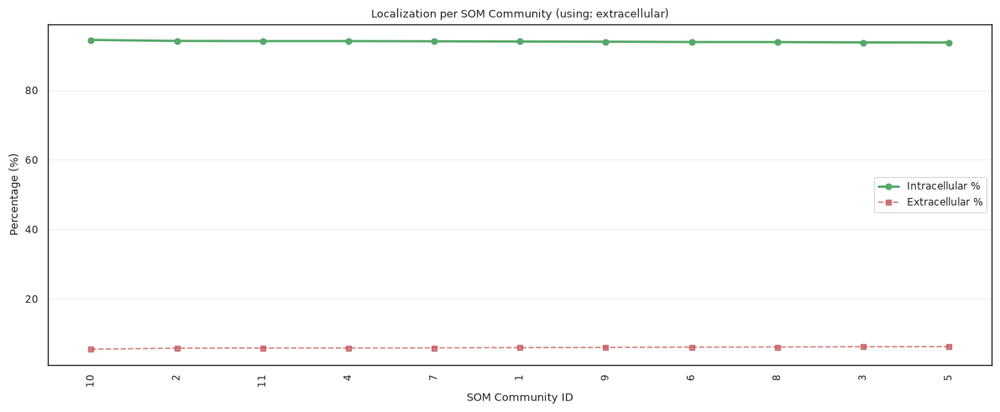

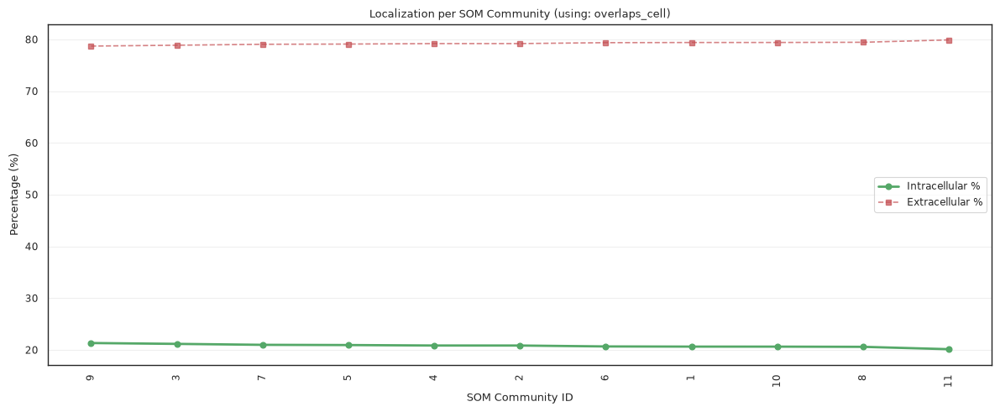

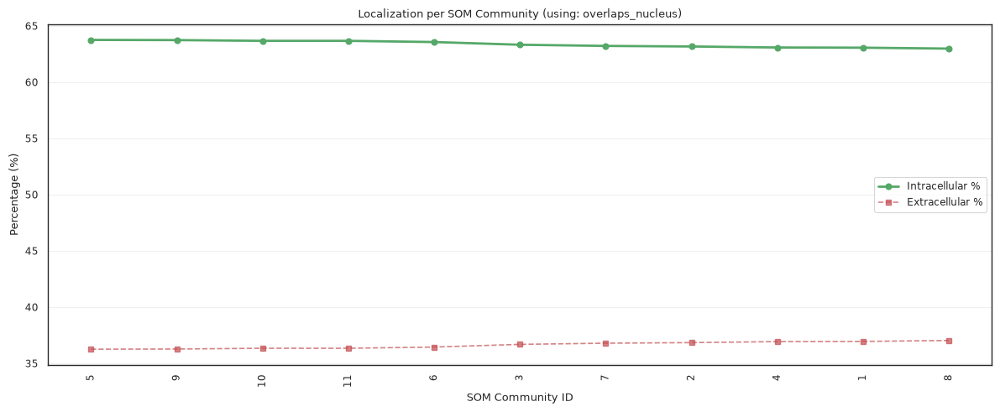

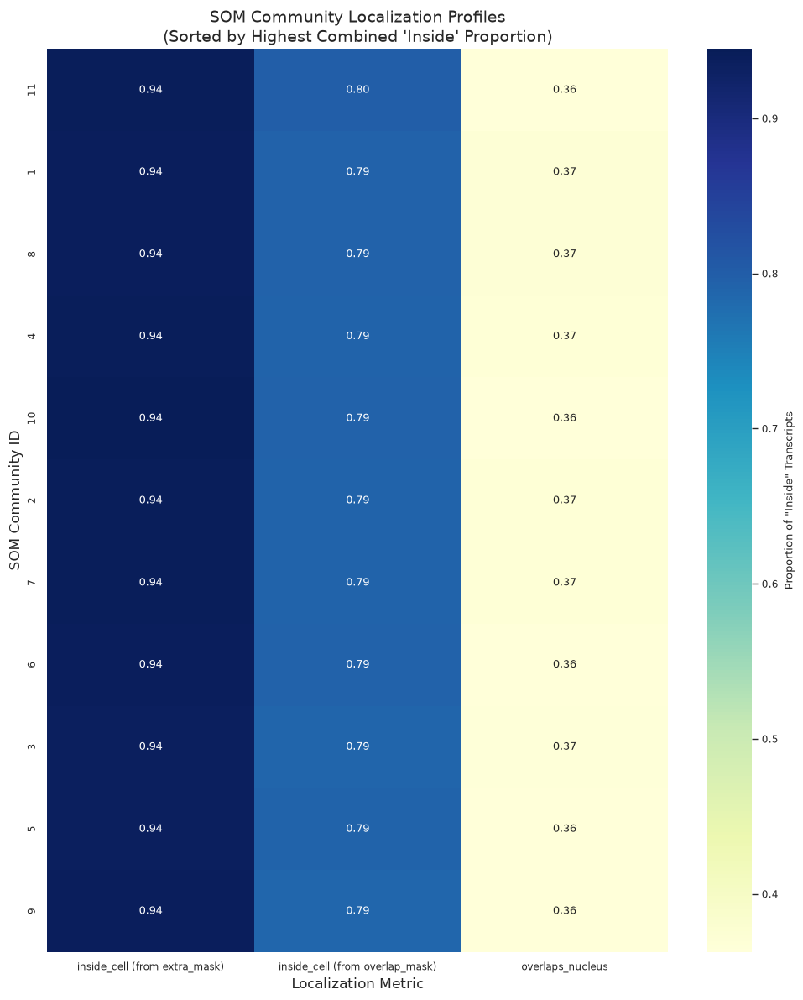

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

def map_som_communities_to_transcripts(
    sdata, 
    background_image, 
    mfx, mfy, mx, my, 
    extracellular_key="extracellular"  # <--- New parameter
):
    """
    Maps SOM communities to transcripts and calculates localization stats 
    based on a user-defined 'extracellular' boolean column.
    """
    # 1. Re-run mapping on full dataset
    df_tx = sdata.points["transcripts"].compute()
    
    # Map Global Physical coordinates to Pixel indices
    px = ((df_tx["x"] - mx) * mfx).astype(int)
    py = ((df_tx["y"] - my) * mfy).astype(int)
    
    # 2. Bound Clipping (prevent index errors)
    h, w = background_image.shape
    valid_mask = (px >= 0) & (px < w) & (py >= 0) & (py < h)
    
    df_final = df_tx[valid_mask].copy()
    px_valid = px[valid_mask]
    py_valid = py[valid_mask]
    
    # 3. Extract Cluster ID from Image
    # indexing: background_image[row, col] -> [y, x]
    df_final['som_cluster'] = background_image[py_valid, px_valid]
    
    # 4. Calculate Localization Stats
    # Filter out cluster 0 (background/empty space)
    df_analysis = df_final[df_final['som_cluster'] > 0]
    
    # Check if the key exists to avoid KeyErrors
    if extracellular_key not in df_analysis.columns:
        raise KeyError(f"Column '{extracellular_key}' not found in transcripts. Available: {df_analysis.columns.tolist()}")

    # Group by SOM cluster and aggregate the provided key
    stats = df_analysis.groupby('som_cluster')[extracellular_key].agg(['mean', 'count'])
    stats.columns = ['prop_extra', 'n_transcripts']
    
    # Calculate percentages
    stats['pct_intra'] = (1 - stats['prop_extra']) * 100
    stats['pct_extra'] = stats['prop_extra'] * 100
    
    # 5. Sort by % Intracellular descending
    stats_sorted = stats.sort_values('pct_intra', ascending=False)
    
    # --- Visualization ---
    plt.figure(figsize=(12, 5))
    x_range = range(len(stats_sorted))
    
    plt.plot(x_range, stats_sorted['pct_intra'], 'go-', label='Intracellular %', linewidth=2)
    plt.plot(x_range, stats_sorted['pct_extra'], 'rs--', label='Extracellular %', alpha=0.7)
    
    plt.xticks(x_range, stats_sorted.index, rotation=90)
    plt.ylabel("Percentage (%)")
    plt.xlabel("SOM Community ID")
    plt.title(f"Localization per SOM Community (using: {extracellular_key})")
    plt.legend()
    plt.grid(axis='y', alpha=0.3)
    plt.tight_layout()
    plt.show()
    
    return stats_sorted

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import logging
logging.getLogger('matplotlib.font_manager').setLevel(logging.ERROR)

def plot_combined_localization_heatmap(sdata, background_image, mfx, mfy, mx, my):
    # 1. Run the mapping for all three keys
    # We'll use a helper to get the raw proportions for each
    keys = ["extracellular", "overlaps_cell", "overlaps_nucleus"]
    results = {}
    
    for key in keys:
        try:
            # Re-using your logic to get the stats for each key
            stats = map_som_communities_to_transcripts(
                sdata, background_image, mfx, mfy, mx, my, 
                extracellular_key=key
            )
            # We want the proportion (mean), not the percentage for the heatmap
            results[key] = stats['prop_extra'] 
        except Exception as e:
            print(f"Skipping {key}: {e}")

    # 2. Create the combined DataFrame
    combined_df = pd.DataFrame(results)

    # 3. ALIGN DIRECTIONS: 
    # 'extracellular' is 1 when outside. 
    # 'overlaps_cell' and 'overlaps_nucleus' are 1 when inside.
    # Let's make them all "Proportion Inside"
    if 'extracellular' in combined_df.columns:
        combined_df['extracellular'] = 1 - combined_df['extracellular']
        combined_df = combined_df.rename(columns={'extracellular': 'inside_cell (from extra_mask)'})
    
    if 'overlaps_cell' in combined_df.columns:
        combined_df = combined_df.rename(columns={'overlaps_cell': 'inside_cell (from overlap_mask)'})

    # 4. SORT by aggregated higher proportion (mean across all columns)
    combined_df['total_score'] = combined_df.mean(axis=1)
    combined_df = combined_df.sort_values('total_score', ascending=False)
    plot_data = combined_df.drop(columns=['total_score'])

    # 5. Plot Heatmap
    plt.figure(figsize=(10, 12))
    sns.heatmap( plot_data,  cmap="YlGnBu", annot=True, fmt=".2f", 
        cbar_kws={'label': 'Proportion of "Inside" Transcripts'})
    plt.title("SOM Community Localization Profiles\n(Sorted by Highest Combined 'Inside' Proportion)", fontsize=14)
    plt.xlabel("Localization Metric", fontsize=12)
    plt.ylabel("SOM Community ID", fontsize=12)
    plt.tight_layout()
    plt.show()
    return combined_df

# Execute
combined_results = plot_combined_localization_heatmap(sdata, background_image, mfx, mfy, mx, my)


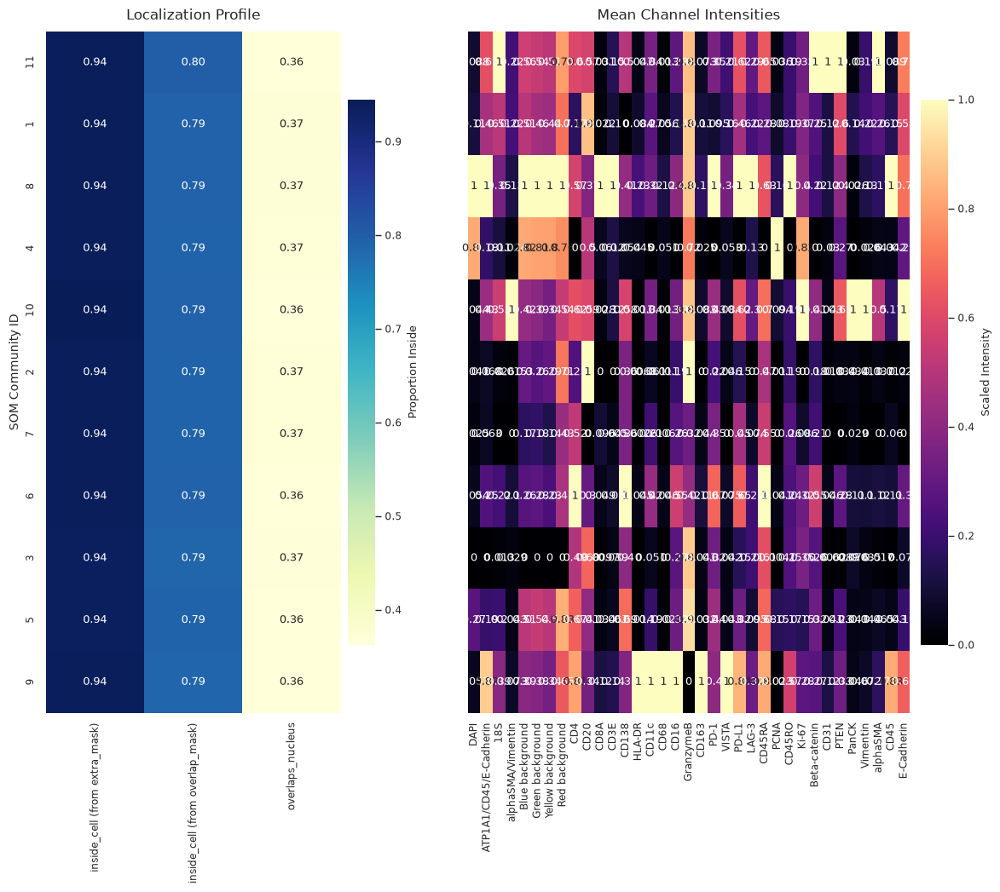

In [19]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
import matplotlib.gridspec as gridspec

def plot_som_full_profile_refined(combined_localization_df, df_som_intensities):
    # 1. Align Data
    common_ids = combined_localization_df.index.intersection(df_som_intensities.index)
    loc_data = combined_localization_df.loc[common_ids].drop(columns=['total_score'], errors='ignore')
    int_data = df_som_intensities.loc[common_ids]

    # 2. Scale Intensities for visualization (0-1 range)
    scaler = MinMaxScaler()
    int_data_scaled = pd.DataFrame(
        scaler.fit_transform(int_data), 
        index=int_data.index, 
        columns=int_data.columns
    )

    # 3. Create Figure with custom GridSpec
    # width_ratios: [1, 1.5] prevents the channels side from becoming too wide
    fig = plt.figure(figsize=(14, 10))
    gs = gridspec.GridSpec(1, 2, width_ratios=[1, 1.5], wspace=0.15)
    
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])

    # --- Panel 1: Localization ---
    sns.heatmap(
        loc_data, 
        ax=ax1, 
        cmap="YlGnBu", 
        annot=True, 
        fmt=".2f", 
        cbar_kws={'label': 'Proportion Inside', 'pad': 0.02, 'shrink': 0.8}
    )
    ax1.set_title("Localization Profile", fontsize=12, pad=10)
    ax1.set_ylabel("SOM Community ID", fontsize=10)

    # --- Panel 2: Intensities ---
    sns.heatmap(
        int_data_scaled, 
        ax=ax2, 
        cmap="magma", 
        annot=True, 
        yticklabels=False, # Hide Y labels on second panel since they are shared
        cbar_kws={'label': 'Scaled Intensity', 'pad': 0.02, 'shrink': 0.8}
    )
    ax2.set_title("Mean Channel Intensities", fontsize=12, pad=10)
    ax2.set_ylabel("") 

    # Clean up layout to prevent label overlap
    plt.subplots_adjust(left=0.1, right=0.9, top=0.9, bottom=0.1)
    plt.show()

# Run the refined plot
plot_som_full_profile_refined(combined_results, df_som_intensities)

# Compositional differences

In [227]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def analyze_som_composition(sdata, background_image, mfx, mfy, mx, my, gene_key="gene"):
    # 1. Map transcripts to pixels (using the same logic as before)
    df_tx = sdata.points["transcripts"].compute()
    px = ((df_tx["x"] - mx) * mfx).astype(int)
    py = ((df_tx["y"] - my) * mfy).astype(int)
    
    h, w = background_image.shape
    valid_mask = (px >= 0) & (px < w) & (py >= 0) & (py < h)
    
    df_mapped = df_tx[valid_mask].copy()
    df_mapped['som_cluster'] = background_image[py[valid_mask], px[valid_mask]]
    
    # Filter out background (ID 0)
    df_mapped = df_mapped[df_mapped['som_cluster'] > 0]

    # 2. Create the Counts Matrix (Contingency Table)
    # Rows = SOM Clusters, Columns = Genes/Types
    df_counts = pd.crosstab(df_mapped['som_cluster'], df_mapped[gene_key])

    return df_counts

# --- Execution ---
# This returns the raw counts dataframe
df_som_composition = analyze_som_composition(sdata, background_image, mfx, mfy, mx, my)

# View the result
# print(df_som_composition.head())

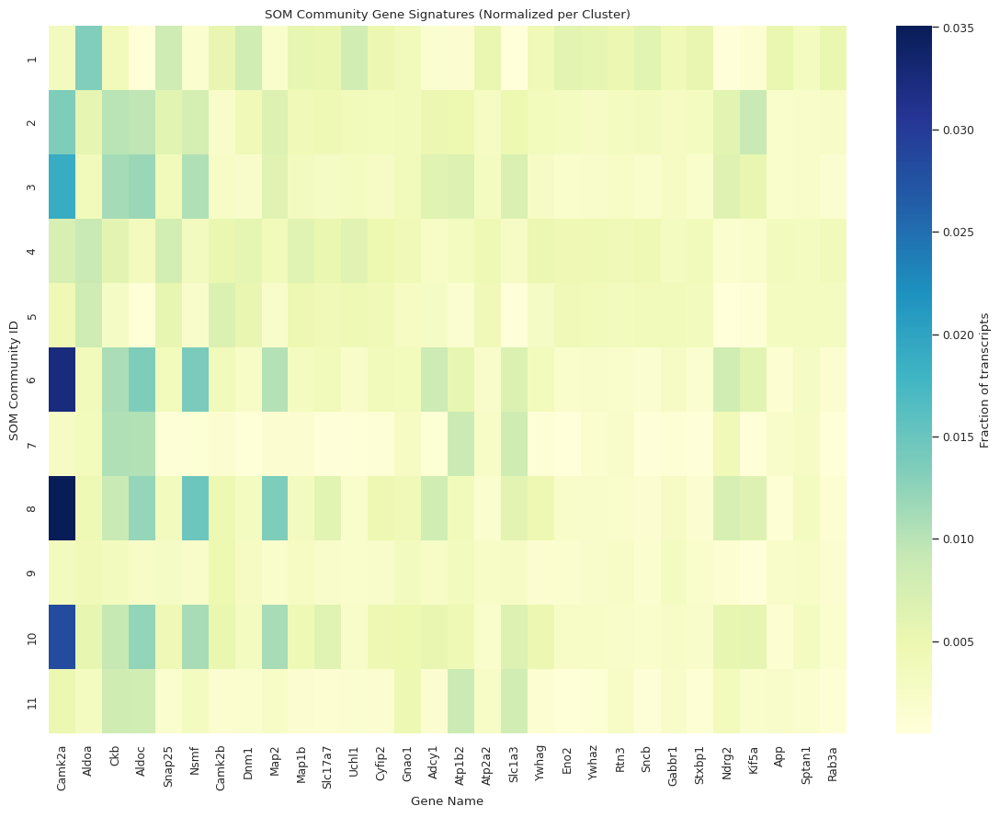

In [228]:
import seaborn as sns
import matplotlib.pyplot as plt

def visualize_som_signatures(df_counts):
    # 1. Normalize by Row (Proportions)
    df_prop = df_counts.div(df_counts.sum(axis=1), axis=0)
    
    # 2. Filter for visibility (optional: keep only top 30 most frequent genes)
    top_genes = df_counts.sum(axis=0).sort_values(ascending=False).head(30).index
    df_plot = df_prop[top_genes]

    # 3. Plot Heatmap
    plt.figure(figsize=(14, 10))
    sns.heatmap(df_plot, cmap="YlGnBu", annot=False, cbar_kws={'label': 'Fraction of transcripts'})
    plt.title("SOM Community Gene Signatures (Normalized per Cluster)")
    plt.xlabel("Gene Name")
    plt.ylabel("SOM Community ID")
    plt.show()
    
    return df_prop

df_prop = visualize_som_signatures(df_som_composition)

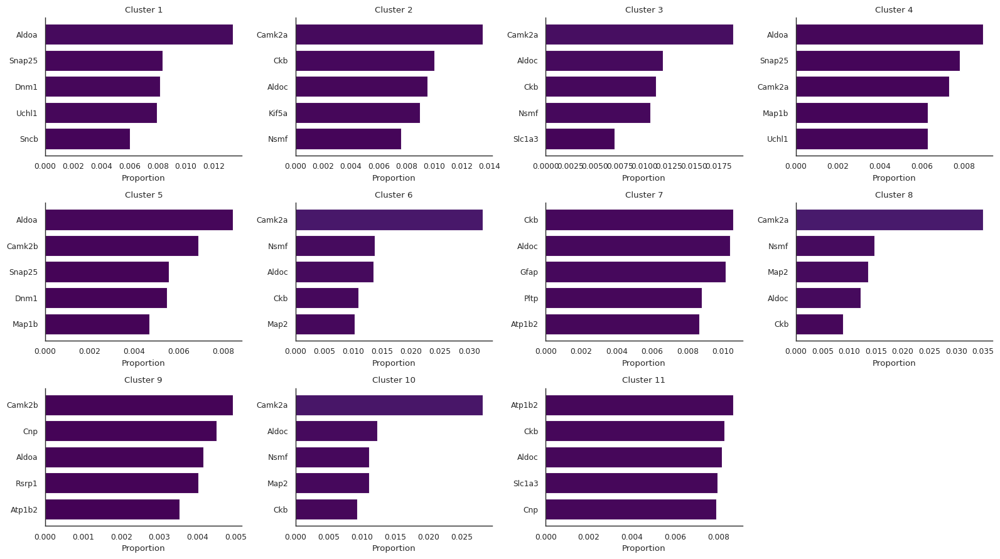

In [229]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

def plot_top_enriched_genes(df_counts, n_top=5):
    """
    Identifies the top N genes per cluster and visualizes them in a faceted plot.
    """
    # 1. Convert Counts to Proportions (Normalized per cluster)
    df_prop = df_counts.div(df_counts.sum(axis=1), axis=0)
    
    top_genes_list = []
    
    # 2. Iterate through each community to find top genes
    for cluster_id in df_counts.index:
        # Get top genes by proportion
        top = df_prop.loc[cluster_id].sort_values(ascending=False).head(n_top)
        
        for gene, val in top.items():
            top_genes_list.append({
                'community_id': cluster_id,
                'gene': gene,
                'proportion': val,
                'count': df_counts.loc[cluster_id, gene]
            })
            
    df_top = pd.DataFrame(top_genes_list)
    
    # 3. Visualization: Faceted Bar Chart
    # We'll plot a subset of clusters if you have many, or all if feasible.
    unique_clusters = df_top['community_id'].unique()
    n_clusters = len(unique_clusters)
    
    # Determine grid size (e.g., 4 columns)
    ncols = 4
    nrows = (n_clusters + ncols - 1) // ncols
    
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, nrows * 3), sharex=False)
    axes = axes.flatten()
    
    for i, cluster_id in enumerate(unique_clusters):
        subset = df_top[df_top['community_id'] == cluster_id].sort_values('proportion', ascending=True)
        
        ax = axes[i]
        ax.barh(subset['gene'], subset['proportion'], color=plt.cm.viridis(subset['proportion'] * 2))
        ax.set_title(f"Cluster {cluster_id}")
        ax.set_xlabel("Proportion")
        ax.spines['top'].set_visible(False)
        ax.spines['right'].set_visible(False)
        
    # Hide empty subplots
    for j in range(i + 1, len(axes)):
        axes[j].axis('off')
        
    plt.tight_layout()
    plt.show()
    
    return df_top

# --- Execution ---
# Using the df_som_composition we generated earlier
df_top_5_genes = plot_top_enriched_genes(df_som_composition, n_top=5)

# View the result DataFrame
# print(df_top_5_genes.head(10))

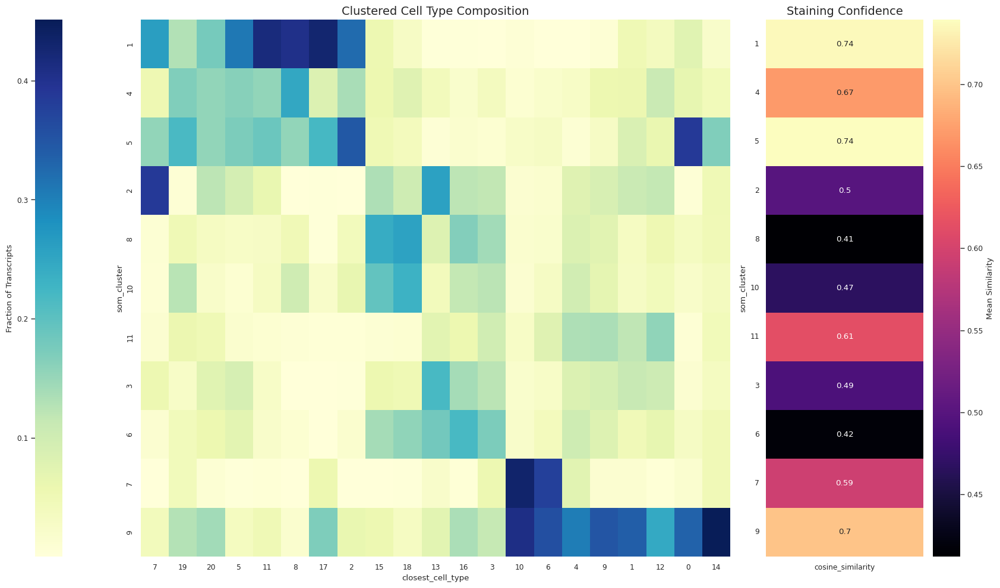

In [236]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import linkage, dendrogram, leaves_list

def analyze_som_vs_celltypes(sdata, background_image, mfx, mfy, mx, my, 
                               cell_type_key='closest_cell_type', 
                               cosine_key='cosine_similarity'):
    # 1. Map transcripts to pixels
    df_tx = sdata.points["transcripts"].compute()
    
    px = ((df_tx["x"] - mx) * mfx).astype(int)
    py = ((df_tx["y"] - my) * mfy).astype(int)
    
    h, w = background_image.shape
    valid_mask = (px >= 0) & (px < w) & (py >= 0) & (py < h)
    
    df_mapped = df_tx[valid_mask].copy()
    df_mapped['som_cluster'] = background_image[py[valid_mask], px[valid_mask]]
    df_mapped = df_mapped[df_mapped['som_cluster'] > 0]

    # 2. Composition: Cell Type per SOM Community
    cell_comp = pd.crosstab(df_mapped['som_cluster'], df_mapped[cell_type_key], normalize='columns')

    # 3. Confidence: Mean Similarity
    som_confidence = df_mapped.groupby('som_cluster')[cosine_key].mean()

    # --- NEW: Hierarchical Clustering / Sorting ---
    if cell_comp.shape[0] > 1 and cell_comp.shape[1] > 1:
        # Sort Columns (Cell Types)
        col_linkage = linkage(cell_comp.T, method='ward')
        col_order = leaves_list(col_linkage)
        cell_comp = cell_comp.iloc[:, col_order]

        # Sort Rows (SOM Communities)
        row_linkage = linkage(cell_comp, method='ward')
        row_order = leaves_list(row_linkage)
        cell_comp = cell_comp.iloc[row_order, :]
        
        # Align confidence scores to the new row order
        som_confidence = som_confidence.loc[cell_comp.index]

    # --- Visualization ---
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 10), gridspec_kw={'width_ratios': [2, 0.5]})

    # Panel 1: Sorted Cell Type Heatmap
    sns.heatmap(cell_comp, annot=False, cmap="YlGnBu", ax=ax1, 
                cbar_kws={'label': 'Fraction of Transcripts', 'location': 'left'})
    ax1.set_title("Clustered Cell Type Composition", fontsize=14)

    # Panel 2: Aligned Staining Confidence
    conf_df = pd.DataFrame(som_confidence)
    sns.heatmap(conf_df, annot=True, cmap="magma", ax=ax2, cbar_kws={'label': 'Mean Similarity'})
    ax2.set_title("Staining Confidence", fontsize=14)
    ax2.set_yticklabels(cell_comp.index, rotation=0) # Ensure Y-labels match the new order

    plt.tight_layout()
    plt.show()

    return cell_comp, som_confidence

# Execute
cell_comp_df, confidence_df = analyze_som_vs_celltypes(sdata, background_image, mfx, mfy, mx, my)

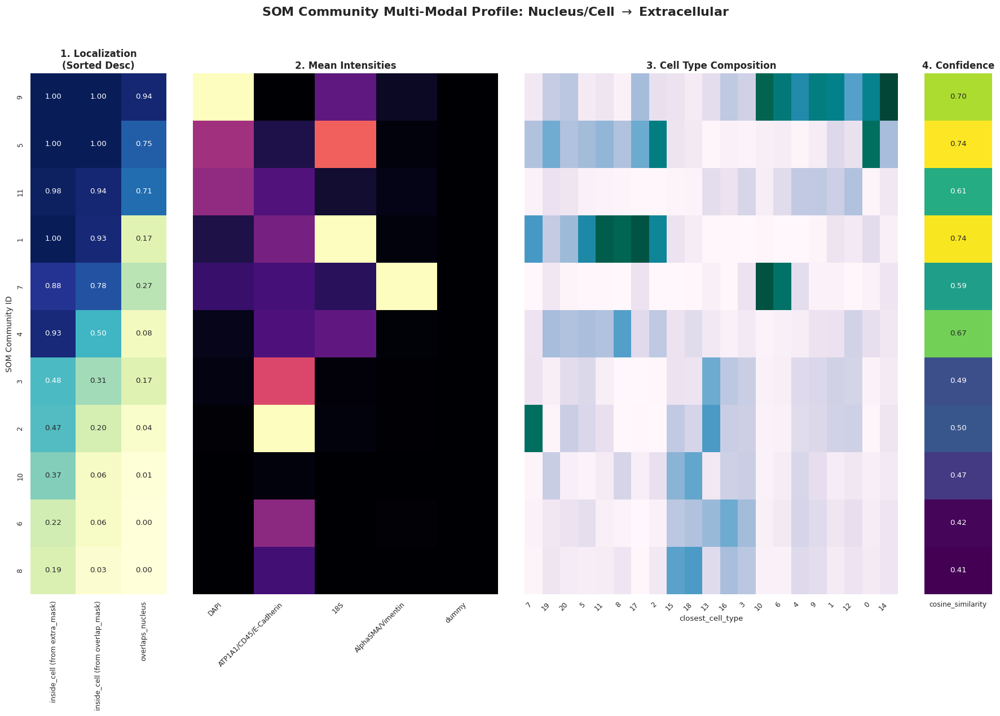

In [238]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from sklearn.preprocessing import MinMaxScaler

def plot_som_aggregated_dashboard(combined_loc, df_intensities, cell_comp, confidence_df):
    """
    Plots a 4-panel dashboard sorted by the aggregate 'Inside' score.
    """
    # 1. Align all DataFrames
    common_ids = combined_loc.index.intersection(df_intensities.index).intersection(cell_comp.index)
    
    # Calculate the aggregate 'Inside' score for sorting
    # This uses the 'total_score' column we created earlier (average of the 3 overlaps)
    loc_data = combined_loc.loc[common_ids].copy()
    if 'total_score' not in loc_data.columns:
        loc_data['total_score'] = loc_data[['extracellular', 'overlaps_cell', 'overlaps_nucleus']].mean(axis=1)
    
    # 2. Sort Descending by the aggregate score
    loc_data = loc_data.sort_values('total_score', ascending=False)
    sorted_ids = loc_data.index
    
    # Reorder everything else to match
    loc_plot = loc_data.drop(columns=['total_score'])
    int_data = df_intensities.loc[sorted_ids]
    cell_data = cell_comp.loc[sorted_ids]
    conf_data = pd.DataFrame(confidence_df.loc[sorted_ids])

    # 3. Scaling for Intensity Panel
    scaler = MinMaxScaler()
    int_data_scaled = pd.DataFrame(
        scaler.fit_transform(int_data), 
        index=int_data.index, 
        columns=int_data.columns
    )

    # 4. Create Figure with custom GridSpec
    fig = plt.figure(figsize=(22, 12))
    # Adjusted ratios: Localization is narrow, Intensities/Cell Types are wider
    gs = gridspec.GridSpec(1, 4, width_ratios=[0.8, 1.8, 2.2, 0.4], wspace=0.12)
    
    ax1 = fig.add_subplot(gs[0])
    ax2 = fig.add_subplot(gs[1])
    ax3 = fig.add_subplot(gs[2])
    ax4 = fig.add_subplot(gs[3])

    # --- Panel 1: Localization (The Sorting Key) ---
    sns.heatmap(loc_plot, ax=ax1, cmap="YlGnBu", annot=True, fmt=".2f", cbar=False)
    ax1.set_title("1. Localization\n(Sorted Desc)", fontsize=12, fontweight='bold')
    ax1.set_ylabel("SOM Community ID", fontsize=10)

    # --- Panel 2: Protein Intensities ---
    sns.heatmap(int_data_scaled, ax=ax2, cmap="magma", yticklabels=False, cbar=False)
    ax2.set_title("2. Mean Intensities", fontsize=12, fontweight='bold')
    plt.setp(ax2.get_xticklabels(), rotation=45, ha='right')

    # --- Panel 3: Cell Type Composition ---
    sns.heatmap(cell_data, ax=ax3, cmap="PuBuGn", yticklabels=False, cbar=False)
    ax3.set_title("3. Cell Type Composition", fontsize=12, fontweight='bold')
    plt.setp(ax3.get_xticklabels(), rotation=45, ha='right')

    # --- Panel 4: Confidence ---
    sns.heatmap(conf_data, ax=ax4, cmap="viridis", annot=True, fmt=".2f", yticklabels=False, cbar=False)
    ax4.set_title("4. Confidence", fontsize=12, fontweight='bold')

    plt.suptitle("SOM Community Multi-Modal Profile: Nucleus/Cell $\\rightarrow$ Extracellular", 
                 fontsize=16, fontweight='bold', y=0.98)
    
    plt.tight_layout(rect=[0, 0.03, 1, 0.95])
    plt.show()

# --- Execution ---
plot_som_aggregated_dashboard(combined_results, df_som_intensities, cell_comp_df, confidence_df)

In [ ]:
## Add results as labels

In [ ]:
import spatialdata as sd
from spatialdata.models import Labels2DModel
from spatialdata.transformations import Identity

# Create the Labels element
labels_element = Labels2DModel.parse(
    background_image, 
    dims=("y", "x"), 
    transformations={"global": Identity()}
)

In [ ]:
# 'som_communities' is the name your new layer will have inside sdata
sdata.labels["som_communities"] = labels_element
# 1. Compute and subsample
transcripts = sdata.points["transcripts"].compute()
subsampled_df = transcripts.sample(frac=0.01, random_state=42)
# 2. Re-parse into a PointsModel and update the layer
sdata.points["transcripts"] = sd.models.PointsModel.parse(subsampled_df)

In [ ]:
sdata.points["transcripts"] = sd.models.PointsModel.parse(subsampled_df.reset_index())

In [ ]:
import geopandas as gpd
import numpy as np
import pandas as pd
import scanpy as sc
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
from scipy.spatial import KDTree
from shapely import linearrings, polygons
from shapely.geometry import box
from sklearn.neighbors import NearestNeighbors
from sklearn.preprocessing import OneHotEncoder
from spatialdata import SpatialData
from spatialdata.models import ShapesModel, PointsModel # FIX: Added PointsModel
from tqdm import tqdm

def _make_squares(centroid_coordinates: np.ndarray, half_widths: list[float]) -> ShapesModel:
    linear_rings = []
    for centroid, half_width in zip(centroid_coordinates, half_widths, strict=False):
        min_coords = centroid - half_width
        max_coords = centroid + half_width
        linear_rings.append(
            linearrings([
                [min_coords[0], min_coords[1]],
                [min_coords[0], max_coords[1]],
                [max_coords[0], max_coords[1]],
                [max_coords[0], min_coords[1]],
            ])
        )
    s = polygons(linear_rings)
    polygon_series = gpd.GeoSeries(s)
    cell_polygon_table = gpd.GeoDataFrame(geometry=polygon_series)
    # FIX: Ensure transformations are passed if needed, here default to Identity
    return ShapesModel.parse(cell_polygon_table)

def create_grid_squares(sdata: SpatialData, layer: str = "transcripts", square_size: float = 50) -> tuple[ShapesModel, np.ndarray]:
    transcripts = sdata.points[layer]
    # FIX: Compute bounds eagerly to avoid Dask-Expression metadata mismatches
    bounds = transcripts[["x", "y"]].compute()
    x_min, y_min = bounds.min().values
    x_max, y_max = bounds.max().values

    x_coords = np.arange(x_min + square_size / 2, x_max, square_size)
    y_coords = np.arange(y_min + square_size / 2, y_max, square_size)

    centroid_coordinates = np.array([[x, y] for x in x_coords for y in y_coords])
    half_widths = [square_size / 2] * len(centroid_coordinates)

    return _make_squares(centroid_coordinates, half_widths), centroid_coordinates

def aggregate_urna(
    sdata: SpatialData,
    layer: str = "transcripts",
    gene_key: str = "gene",
    method: str = "bin",
    square_size: float = 50,
    radius: float = 50,
    knn_k: int = 5,
    extracellular_only: bool = True,
    copy: bool = False,
    key_added: str | None = None,
    cell_type_key: str = "leiden",
    embedding_enabled: bool = True,
    fragment_k: int = 5,
    fragment_dist_thresh: float = 7.0,
    fragment_sim_thresh: float = 0.5,
):
    if copy:
        sdata = sdata.copy()

    # FIX: Improved Extracellular Selection to avoid the "Item wrong length" error
    # We compute the mask and the dataframe in a single step to ensure alignment
    points_element = sdata.points[layer]
    
    if extracellular_only:
        # Avoid computing the mask separately from the dataframe
        full_df = points_element.compute()
        extracell_df = full_df[full_df["extracellular"] == True].copy()
    else:
        extracell_df = points_element.compute()

    if method == "bin":
        # Generate bounds
        x_min, x_max = extracell_df["x"].min(), extracell_df["x"].max()
        y_min, y_max = extracell_df["y"].min(), extracell_df["y"].max()

        xs = np.arange(x_min, x_max + square_size, square_size)
        ys = np.arange(y_min, y_max + square_size, square_size)

        grid_squares = []
        centroids = []
        for x in xs[:-1]:
            for y in ys[:-1]:
                square = box(x, y, x + square_size, y + square_size)
                grid_squares.append(square)
                centroids.append((x + square_size / 2, y + square_size / 2))

        grid_gdf = gpd.GeoDataFrame({"geometry": grid_squares})
        sdata.shapes["grid_squares"] = ShapesModel.parse(grid_gdf)

        # FIX: Wrap the Pandas DataFrame back into a PointsModel before assignment
        # SpatialData __setitem__ will reject a raw Pandas DataFrame
        sdata.points["extracellular_transcripts"] = PointsModel.parse(
            extracell_df, 
            coordinates={'x': 'x', 'y': 'y'}
        )

        # Aggregate transcript counts
        sdata_shapes = sdata.aggregate(
            values="extracellular_transcripts", 
            by="grid_squares", 
            value_key=gene_key, 
            agg_func="count"
        )

        if not key_added:
            key_added = "segmentation_free_table"
            
        # FIX: Ensure table is handled correctly as AnnData
        sdata.tables[key_added] = sdata_shapes["table"]
        sdata.tables[key_added].obsm["spatial"] = np.array(centroids)

    elif method in ["radius", "knn"]:
        # (Combined logic for brevity as they share the same DF requirements)
        df = extracell_df
        df[gene_key] = df[gene_key].astype(str)
        gene_cat = pd.Categorical(df[gene_key])
        codes = gene_cat.codes
        unique_genes = np.array(gene_cat.categories)
        n_genes = len(unique_genes)

        coords = df[["x", "y"]].to_numpy()
        tree = KDTree(coords)
        
        if method == "radius":
            indices_list = tree.query_ball_point(coords, r=radius)
            desc = "Computing radius-based signatures"
        else:
            _, indices_list = tree.query(coords, k=knn_k)
            desc = "Computing KNN-based signatures"

        signatures = [np.bincount(codes[idx], minlength=n_genes) for idx in tqdm(indices_list, desc=desc)]
        
        signature_table = pd.DataFrame(signatures, index=df.index, columns=unique_genes)
        adata_sig = sc.AnnData(signature_table)

        if not key_added:
            key_added = "segmentation_free_table"
        
        sdata.tables[key_added] = adata_sig
        sdata.tables[key_added].obsm["spatial"] = coords

    elif method == "fragments":
        # ... (logic for fragments remains similar, but ensure assignments use .tables or .points)
        df = extracell_df.loc[:, ["x", "y", gene_key]].rename(columns={gene_key: "gene"})

        if embedding_enabled:
            # FIX: Access table via .tables if using newer SpatialData
            adata_ref = sdata.table if "table" in sdata.tables else sdata.tables[next(iter(sdata.tables))]
            gene_embeddings = compute_gene_embeddings_from_anndata(adata_ref, cell_type_col=cell_type_key)
        else:
            gene_embeddings = None

        labels = aggregate_fragments(df, gene_embeddings=gene_embeddings, k=fragment_k, 
                                     dist_thresh=fragment_dist_thresh, sim_thresh=fragment_sim_thresh)
        df["fragment_id"] = labels
        signature_table = pd.crosstab(df["fragment_id"], df["gene"])
        adata_frag = sc.AnnData(signature_table)

        centroids = compute_fragment_centroids(df, fragment_col="fragment_id")
        centroids = centroids.set_index("fragment_id")
        centroids = centroids.loc[adata_frag.obs.index.astype(int)]
        adata_frag.obsm["spatial"] = centroids[["x_centroid", "y_centroid"]].to_numpy()

        if not key_added:
            key_added = "segmentation_free_table"
        sdata.tables[key_added] = adata_frag

    return sdata if copy else None

In [ ]:
aggregate_urna(sdata, extracellular_only=False,layer='transcripts',square_size=10)

In [ ]:
sdata['segmentation_free_table']

# Work on multimodal 

In [ ]:
# 1. Compute and subsample
transcripts = sdata.points["transcripts"].compute()
subsampled_df = transcripts.sample(frac=0.01, random_state=42)
# 2. Re-parse into a PointsModel and update the layer
sdata.points["transcripts"] = sd.models.PointsModel.parse(subsampled_df)

In [ ]:
import numpy as np
import scanpy as sc
import spatialdata as sd
import xarray as xr


def image_intensities_per_transcript(
    sdata: sd.SpatialData,
    image_key: str,
    scale: str,
    transcript_key: str,
    extracellular: bool = False,
    copy: bool = True,
    gene_key: str = "gene",
) -> sd.SpatialData:
    """
    Extracts image intensities at transcript locations and adds them as a new layer in the SpatialData object.

    Args:
        sdata
            The input SpatialData object.
        image_key
            The key for the image layer in sdata.images.
        scale
            The scale of the image to use.
        transcript_key
            The key for the transcript points in sdata.points.
        extracellular
            Whether to include only extracellular transcripts (default: False). If True, only transcripts where `extracellular` is True are used. If false, all transcripts are used.
        copy
            Whether to create a copy of the SpatialData object (default: True).

    Returns
    -------
        A SpatialData object with the added 'transcripts_image_intensities' layer.  If copy=True, a new SpatialData object is returned. Otherwise, the original sdata object is modified and returned.

    Raises
    ------
        KeyError: If the specified image or transcript key is not found in the SpatialData object.
    """
    try:
        image = sdata.images[image_key][scale]  # Image as xarray.DataArray
        transcripts = sdata.points[transcript_key].compute()  # Transcript coordinates
    except KeyError as e:
        raise KeyError(f"Key not found in sdata: {e}")  # noqa: B904

    imarray = image.image.compute()

    minx = transcripts.x.min()
    maxx = transcripts.x.max()
    transcripts_size_x = maxx - minx
    image_size_x = imarray.shape[2]
    multi_factor_x = image_size_x / transcripts_size_x

    miny = transcripts.y.min()
    maxy = transcripts.y.max()
    transcripts_size_y = maxy - miny
    image_size_y = imarray.shape[1]
    multi_factor_y = image_size_y / transcripts_size_y

    transcripts["x_scaled"] = (transcripts["x"] - minx) * multi_factor_x
    transcripts["y_scaled"] = (transcripts["y"] - miny) * multi_factor_y

    if extracellular:
        transcripts = transcripts[transcripts["extracellular"]]  # Select extracellular transcripts
    else:
        transcripts = transcripts

    # Get (x, y) coordinates of transcripts
    xy_positions = np.column_stack((transcripts["x_scaled"], transcripts["y_scaled"]))
    xy_positions_raw = np.column_stack((transcripts["x"], transcripts["y"]))

    # Interpolate or fetch nearest pixel values
    intensities = image.sel(
        x=xr.DataArray(xy_positions[:, 0], dims="points"), y=xr.DataArray(xy_positions[:, 1], dims="points"), method="nearest"
    )  # Use "linear" for interpolation

    intensity_tab = np.zeros([len(intensities.x.values), 2])
    intensity_tab[:, 0] = intensities.x.values
    intensity_tab[:, 1] = intensities.y.values

    ad_data = intensities.image.values.transpose()
    if ad_data.ndim == 2:  # Check if it is a 2D image
        ad = sc.AnnData(ad_data)
        ad.var.index = intensities.c.values
    else:  # If not, assume it is a 3D image and flatten the last dimension
        ad = sc.AnnData(ad_data.reshape(ad_data.shape[0], -1))
        ad.var.index = [f"{c}_{z}" for c in intensities.c.values for z in range(ad_data.shape[2])]  # Create combined channel and z-slice names.

    ad.obs[gene_key] = list(transcripts[gene_key])  # Add feature names
    ad.obsm["spatial"] = xy_positions_raw  # Add raw spatial coordinates

    # Add the AnnData object as a new spatial data object
    sdata["image_intensity_per_transcript"] = ad

    return sdata if copy else None

import numpy as np
import pandas as pd
from scipy.stats import gaussian_kde
from sklearn.metrics.pairwise import cosine_similarity
import spatialdata as sd

def refine_urna_by_probabilistic_similarity(
    sdata: sd.SpatialData,
    intensity_adata_key: str = "image_intensity_per_transcript",
    prob_threshold: float = 0.5,copy=False,
):
    # 1. Prepare Data
    transcripts = sdata.points["transcripts"].compute().copy()
    adata = sdata[intensity_adata_key]
    
    # Positional index to map correctly to AnnData rows (0 to N-1)
    transcripts['matrix_pos'] = np.arange(len(transcripts))
    intensity_matrix = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X
    
    if len(transcripts) != intensity_matrix.shape[0]:
        raise ValueError(f"Shape mismatch: Transcripts ({len(transcripts)}) vs Matrix ({intensity_matrix.shape[0]})")

    # 2. Compute "Cellular Reference" Signatures 
    # Using 'closest_cell_type' from assigned transcripts only
    cell_mask = transcripts['overlaps_cell'] == True
    
    signatures = {}
    unique_types = transcripts.loc[cell_mask, 'closest_cell_type'].unique()
    
    for ct in unique_types:
        if pd.isna(ct) or ct == "UNASSIGNED": continue
        
        pos_indices = transcripts.loc[(transcripts['closest_cell_type'] == ct) & cell_mask, 'matrix_pos'].values
        if len(pos_indices) > 5: 
            signatures[ct] = intensity_matrix[pos_indices].mean(axis=0)

    if not signatures:
        print("Warning: No cellular signatures found. Check 'overlaps_cell' and 'closest_cell_type'.")
        return sdata

    sig_matrix = np.array(list(signatures.values()))

    # 3. Calculate Similarity for ALL transcripts (Intra + Extra)
    print("Calculating cosine similarities...")
    all_similarities = cosine_similarity(intensity_matrix, sig_matrix)
    transcripts["max_cosine_sim"] = all_similarities.max(axis=1)

    # 4. Bayesian Posterior Calculation
    # We compare the similarity distribution of 'Known Cellular' vs 'Potential URNA'
    scores_inside = transcripts.loc[transcripts["overlaps_cell"] == True, "max_cosine_sim"].dropna().values
    scores_outside = transcripts.loc[transcripts["overlaps_cell"] == False, "max_cosine_sim"].dropna().values

    if len(scores_inside) > 20 and len(scores_outside) > 20:
        print("Calculating Bayesian probability distributions...")
        kde_in = gaussian_kde(scores_inside)
        kde_out = gaussian_kde(scores_outside)
        
        all_scores = transcripts["max_cosine_sim"].values
        li_in = kde_in(all_scores)
        li_out = kde_out(all_scores)
        
        # Posterior: Probability a transcript belongs to the 'Outside' distribution
        # P(URNA | Similarity) = Likelihood_Out / (Likelihood_Out + Likelihood_In)
        transcripts["prob_is_urna_stainings"] = li_out / (li_out + li_in + 1e-10)
        
        # Log the threshold where P=0.5
        db_idx = np.argmin(np.abs(transcripts["prob_is_urna_stainings"] - 0.5))
        print(f"Probabilistic boundary (P=0.5) found at cosine_similarity: {all_scores[db_idx]:.4f}")
    else:
        print("Insufficient data for KDE. Creating null column.")
        transcripts["prob_is_urna_stainings"] = 0.0

    # 5. Define Extracellular (URNA)
    # Must be physically outside a cell AND match the 'Outside' protein signature
    transcripts["extracellular_stainings"] = (transcripts["overlaps_cell"] == False) & (transcripts["prob_is_urna_stainings"] > prob_threshold)

    # Clean up and update sdata
    output_df = transcripts.drop(columns=['matrix_pos'])
    sdata.points["transcripts"] = sd.models.PointsModel.parse(output_df)
    
    return sdata if copy else None


In [ ]:
image_intensities_per_transcript(sdata, image_key="morphology_focus", scale="scale0", transcript_key="transcripts", extracellular=False, copy=False)

In [ ]:
refine_urna_by_probabilistic_similarity(sdata)

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt

def plot_joint_comparison(df, x_col='prob_is_urna', y_col='prob_is_urna_stainings', hue_col='overlaps_cell', s=2, alpha=0.3):
    """
    Creates a JointPlot with marginal distributions for any two variables in the dataframe.
    """
    # 1. Handle Palette logic
    if hue_col in ['overlaps_cell', 'extracellular', 'extracellular_stainings']:
        palette = {True: '#d62728', False: '#1f77b4'}
    elif df[hue_col].nunique() > 10:
        palette = sns.color_palette("husl", df[hue_col].nunique())
    else:
        palette = "deep"

    # 2. Initialize the JointGrid
    g = sns.JointGrid(data=df, x=x_col, y=y_col, hue=hue_col, palette=palette)

    # 3. Plot the Scatter in the center
    g.plot_joint(sns.scatterplot, s=s, alpha=alpha, edgecolor=None)

    # 4. Plot the Marginal Distributions (KDEs)
    # common_norm=False allows smaller groups (like rare niches) to be visible in density
    g.plot_marginals(sns.kdeplot, fill=True, alpha=0.2, common_norm=False)

    # 5. Dynamic Formatting
    g.fig.set_size_inches(7, 6)
    
    # Clean up labels for the title
    title_x = x_col.replace('_', ' ').title()
    title_y = y_col.replace('_', ' ').title()
    g.fig.suptitle(f"{title_x} vs {title_y}\nColored by: '{hue_col}'", 
                   fontweight='bold', y=1.02)
    
    g.ax_joint.set_xlabel(title_x)
    g.ax_joint.set_ylabel(title_y)

    # 6. Add Consensus line only if axes have similar ranges (e.g., both are 0-1 probabilities)
    x_min, x_max = df[x_col].min(), df[x_col].max()
    y_min, y_max = df[y_col].min(), df[y_col].max()
    
    if (0 <= x_min <= 0.1 and 0.9 <= x_max <= 1.0) and (0 <= y_min <= 0.1 and 0.9 <= y_max <= 1.0):
        g.ax_joint.plot([0, 1], [0, 1], color='black', linestyle='--', alpha=0.4, label='Consensus')
    
    # Legend handling
    plt.legend(title=hue_col.replace('_', ' ').title(), bbox_to_anchor=(1.2, 1), loc='upper left')
    
    plt.show()

# --- Example Usage ---
# df = sdata.points["transcripts"].compute()

# Compare transcriptomic prob vs staining prob
# plot_joint_comparison(df, x_col='prob_is_urna', y_col='prob_is_urna_stainings')

# Compare raw similarity vs staining probability
# plot_joint_comparison(df, x_col='max_cosine_sim', y_col='prob_is_urna_stainings', hue_col='extracellular_stainings')

In [ ]:
# Execution Examples
output_transcripts = sdata.points["transcripts"].compute()

# 1. Color by segmentation status
plot_joint_comparison(output_transcripts, hue_col='overlaps_cell', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')

# 1. Color by segmentation status
plot_joint_comparison(output_transcripts, hue_col='extracellular', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')
plot_joint_comparison(output_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')

In [ ]:
out_transcripts=output_transcripts[output_transcripts['overlaps_cell']==False]
confusion_extracellular=pd.crosstab(out_transcripts['extracellular'],out_transcripts['extracellular_stainings'])
# 1. Color by segmentation status
plot_joint_comparison(out_transcripts, hue_col='overlaps_cell', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')
plot_joint_comparison(out_transcripts, hue_col='extracellular', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='prob_is_urna_stainings')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='nucleus_distance')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='cosine_similarity')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,x_col='prob_is_urna', y_col='assignment_score')
plot_joint_comparison(out_transcripts, hue_col='extracellular_stainings', s=1,y_col='max_cosine_sim', x_col='cosine_similarity')
plot_joint_comparison(out_transcripts, hue_col='extracellular', s=1,y_col='max_cosine_sim', x_col='cosine_similarity')

In [ ]:
from scipy.stats import gaussian_kde

def compute_consensus_urna_probability(df, x_col='cosine_similarity', y_col='max_cosine_sim'):
    """
    Computes a consensus probability of being extracellular using 2D KDE 
    over transcriptomic and staining similarities.
    """
    # 1. Define the two populations in 2D space
    # Inside = 'Ground Truth' Cellular
    # Outside = Potential URNA
    mask_in = df['overlaps_cell'] == True
    mask_out = df['overlaps_cell'] == False
    
    # Prepare coordinates: shape (2, N)
    train_in = np.vstack([df.loc[mask_in, x_col], df.loc[mask_in, y_col]])
    train_out = np.vstack([df.loc[mask_out, x_col], df.loc[mask_out, y_col]])
    
    # 2. Fit 2D KDEs
    print("Fitting 2D Bayesian distributions...")
    kde_in = gaussian_kde(train_in)
    kde_out = gaussian_kde(train_out)
    
    # 3. Evaluate all points
    # We evaluate every transcript's (x, y) pair against both 2D distributions
    all_pts = np.vstack([df[x_col], df[y_col]])
    
    li_in = kde_in(all_pts)
    li_out = kde_out(all_pts)
    
    # 4. Compute 2D Posterior (Uniform Priors)
    df["prob_is_urna_consensus"] = li_out / (li_out + li_in + 1e-10)
    
    return df

In [ ]:
import numpy as np
from scipy.stats import gaussian_kde

def refine_urna_by_consensus_2d_optimized(sdata, transcript_key="transcripts", prob_threshold=0.5):
    transcripts = sdata.points[transcript_key].compute().copy()
    cols = ['cosine_similarity', 'max_cosine_sim']
    
    # 1. Clean data (No NaNs allowed)
    valid_mask = np.isfinite(transcripts[cols]).all(axis=1)
    df_v = transcripts[valid_mask]

    # 2. SUBSAMPLE to train (Learning the 'shape' of the data)
    # We only need a representative slice to build the 2D map
    train_size = 20000 
    df_in = df_v[df_v['overlaps_cell'] == True]
    df_out = df_v[df_v['overlaps_cell'] == False]
    
    s_in = df_in.sample(min(len(df_in), train_size))
    s_out = df_out.sample(min(len(df_out), train_size))

    # Fit the 2D KDEs
    kde_in = gaussian_kde(np.vstack([s_in[cols[0]], s_in[cols[1]]]))
    kde_out = gaussian_kde(np.vstack([s_out[cols[0]], s_out[cols[1]]]))

    # 3. CHUNK the evaluation (Processing in bite-sized pieces)
    probs = np.full(len(transcripts), 0.5, dtype=np.float32)
    valid_idx = np.where(valid_mask)[0]
    all_coords = np.vstack([transcripts.loc[valid_mask, cols[0]], 
                            transcripts.loc[valid_mask, cols[1]]])

    chunk_size = 100000 
    print(f"Processing {all_coords.shape[1]:,} points...")
    
    for i in range(0, all_coords.shape[1], chunk_size):
        end = i + chunk_size
        chunk = all_coords[:, i:end]
        
        li_in = kde_in(chunk)
        li_out = kde_out(chunk)
        
        probs[valid_idx[i:end]] = li_out / (li_out + li_in + 1e-10)

    transcripts["prob_is_urna_consensus"] = probs
    transcripts["extracellular_consensus"] = (transcripts["overlaps_cell"] == False) & \
                                             (transcripts["prob_is_urna_consensus"] > prob_threshold)

    sdata.points[transcript_key] = sd.models.PointsModel.parse(transcripts)
    return sdata

In [ ]:
refine_urna_by_consensus_2d_optimized(sdata, transcript_key="transcripts", prob_threshold=0.5)

# --- STEP 4: Visualize Results ---
df_final = sdata["transcripts"].compute()

# Plot the 2D decision space
plot_joint_comparison(
    df_final, 
    x_col='cosine_similarity', 
    y_col='max_cosine_sim', 
    hue_col='prob_is_urna_consensus'
)

# Work on resegmentation

In [ ]:
zarr_path_segfree = os.path.join(inpath, "data_processed_with_scores.zarr")
sdata=sd.read_zarr(zarr_path_segfree) 


In [ ]:
import pandas as pd
import numpy as np

def extract_transcript_subset(
    sdata, 
    x_range, 
    y_range, 
    layer="transcripts"
):
    """
    Extracts a subset of transcripts as a pandas DataFrame based on spatial boundaries.
    
    Parameters
    ----------
    sdata : spatialdata.SpatialData
        The spatial data object.
    x_range : tuple
        (min_x, max_x)
    y_range : tuple
        (min_y, max_y)
    layer : str, optional
        The points layer to extract from, by default "transcripts".

    Returns
    -------
    pd.DataFrame
        A filtered pandas DataFrame containing transcripts within the ROI.
    """
    # 1. Access the points and compute to pandas
    # Using .compute() ensures we handle the Dask-backed table correctly
    df = sdata.points[layer].compute()

    # 2. Apply spatial filter
    mask = (
        (df["x"] >= x_range[0]) & (df["x"] <= x_range[1]) &
        (df["y"] >= y_range[0]) & (df["y"] <= y_range[1])
    )
    
    subset = df[mask].copy().reset_index(drop=True)
    
    print(f"Extracted {len(subset)} transcripts within X:{x_range}, Y:{y_range}")
    
    return subset

import matplotlib.pyplot as plt
import seaborn as sns

def visualize_roi_transcripts(
    roi_df, 
    cell_id_col="cell_id", 
    unassigned_tag="UNASSIGNED", 
    s=1, 
    figsize=(10, 10)
):
    """
    Plots transcripts in the ROI, coloring by cell_id with unassigned as grey.
    """
    plt.figure(figsize=figsize)
    
    # 1. Separate unassigned and assigned
    unassigned_mask = roi_df[cell_id_col] == unassigned_tag
    assigned_df = roi_df[~unassigned_mask].copy()
    unassigned_df = roi_df[unassigned_mask].copy()
    
    # 2. Plot unassigned first (background)
    plt.scatter(
        unassigned_df["x"], 
        unassigned_df["y"], 
        c="lightgrey", 
        s=s, 
        label="Unassigned", 
        alpha=0.5,
        edgecolors='none'
    )
    
    # 3. Handle assigned cells
    if not assigned_df.empty:
        unique_cells = assigned_df[cell_id_col].unique()
        # Create a color palette with enough colors
        palette = sns.color_palette("husl", len(unique_cells))
        cell_to_color = dict(zip(unique_cells, palette))
        
        # Plot assigned transcripts
        plt.scatter(
            assigned_df["x"], 
            assigned_df["y"], 
            c=assigned_df[cell_id_col].map(cell_to_color), 
            s=s, 
            alpha=0.8,
            edgecolors='none'
        )
    
    plt.gca().set_aspect('equal', adjustable='box')
    plt.title(f"ROI Transcript Map ({len(roi_df)} points)")
    plt.xlabel("X")
    plt.ylabel("Y")
    # Legend can be huge, so we only show the 'Unassigned' and a generic 'Assigned' marker
    plt.legend(markerscale=5)
    plt.show()


In [ ]:
# Usage:
roi_df = extract_transcript_subset(sdata, (4900, 5000), (2800, 3000))
visualize_roi_transcripts(roi_df, unassigned_tag="UNASSIGNED")

In [ ]:
def analyze_resegmentation_needs(
    roi_df, 
    cell_id_col="cell_id", 
    unassigned_tag="UNASSIGNED", 
    sim_factor=0.8,    
    assign_factor=0.7,
    min_sim_recruitment=0.5 # New: Threshold for background reads to be eligible
):
    df = roi_df.copy()
    assigned_mask = df[cell_id_col] != unassigned_tag
    
    # 1. Compute Cell-level Consensus
    cell_stats = df[assigned_mask].groupby(cell_id_col).agg({
        "closest_cell_type": lambda x: x.mode()[0] if not x.empty else unassigned_tag,
        "cosine_similarity": "median",
        "assignment_score": "median"
    }).rename(columns={
        "closest_cell_type": "consensus_type",
        "cosine_similarity": "cell_median_sim",
        "assignment_score": "cell_median_assign"
    })
    
    df = df.merge(cell_stats, on=cell_id_col, how="left")
    
    # 2. Logic Flags
    flag_mismatch = (df[cell_id_col] != unassigned_tag) & (df["closest_cell_type"] != df["consensus_type"])
    low_sim = (df["cosine_similarity"] < (df["cell_median_sim"] * sim_factor))
    low_assign = (df["assignment_score"] < (df["cell_median_assign"] * assign_factor))

    # 3. Define Actions
    df["resegment_action"] = "keep"
    
    # Prune existing members
    df.loc[(df[cell_id_col] != unassigned_tag) & (low_sim | low_assign), "resegment_action"] = "prune"
    
    # Reassign existing members
    df.loc[flag_mismatch & (df["resegment_action"] == "keep"), "resegment_action"] = "reassign"
    
    # RECRUIT: New logic for background transcripts
    # If it's UNASSIGNED but has high similarity, it's a 'recruit' candidate
    recruit_mask = (df[cell_id_col] == unassigned_tag) & (df["cosine_similarity"] >= min_sim_recruitment)
    df.loc[recruit_mask, "resegment_action"] = "recruit"
    
    return df


from scipy.spatial import KDTree

from scipy.spatial import KDTree
import pandas as pd
import numpy as np

def apply_resegmentation_iterative(
    roi_df, 
    cell_id_col="cell_id", 
    unassigned_tag="UNASSIGNED", 
    connectivity_radius=2.0,
    max_iterations=5
):
    """
    Refines cell boundaries iteratively. New recruits can help recruit 
    their neighbors in the next step, allowing for natural biological growth.
    """
    df = roi_df.copy()
    
    # 1. Action: Prune (Remove low-quality noise immediately)
    df.loc[df["resegment_action"] == "prune", cell_id_col] = unassigned_tag
    
    # 2. Setup the target pool (things that WANT to be assigned)
    # This includes mismatches (reassign) and high-quality background (recruit)
    targets_mask = df["resegment_action"].isin(["reassign", "recruit"])
    
    for i in range(max_iterations):
        # Transcripts already having a solid ID act as the "Growth Frontier"
        stable_mask = (df[cell_id_col] != unassigned_tag) & (~targets_mask)
        stable_df = df[stable_mask]
        
        if stable_df.empty:
            break
            
        # Build tree of currently assigned cells
        tree = KDTree(stable_df[["x", "y"]].values)
        
        # Identify which targets are still unassigned/unmoved
        current_targets = df[targets_mask & (df[cell_id_col] == unassigned_tag)]
        if current_targets.empty:
            break
            
        new_assignments = {}
        for idx in current_targets.index:
            target_type = df.loc[idx, "closest_cell_type"]
            coords = df.loc[idx, ["x", "y"]].values.reshape(1, -1)
            
            # Find neighbors within touching distance
            indices = tree.query_ball_point(coords, r=connectivity_radius)[0]
            
            if indices:
                neighbors = stable_df.iloc[indices]
                # Must match the biological identity
                type_matches = neighbors[neighbors["closest_cell_type"] == target_type]
                
                if not type_matches.empty:
                    new_assignments[idx] = type_matches[cell_id_col].mode()[0]

        # Update the dataframe with this round's recruits
        if not new_assignments:
            break # Stop if no more growth is possible
            
        for idx, new_id in new_assignments.items():
            df.at[idx, cell_id_col] = new_id
            # Once assigned, it is no longer a 'target', it becomes 'stable' for the next loop
            
        print(f"Iteration {i+1}: Recruited {len(new_assignments)} transcripts.")

    return df


import matplotlib.pyplot as plt
import seaborn as sns

import matplotlib.pyplot as plt
import seaborn as sns
def visualize_resegmentation_diagnostic(roi_df, cell_id_col="cell_id", unassigned_tag="UNASSIGNED", s=2):
    fig, axes = plt.subplots(1, 4, figsize=(24, 6), sharex=True, sharey=True)
    
    is_unassigned = roi_df[cell_id_col] == unassigned_tag
    
    # Panel 1: Original
    axes[0].scatter(roi_df["x"], roi_df["y"], c="lightgrey", s=s, alpha=0.1)
    axes[0].scatter(roi_df.loc[~is_unassigned, "x"], roi_df.loc[~is_unassigned, "y"], 
                    c="steelblue", s=s, alpha=0.8)
    axes[0].set_title("1. Original Segmented Areas")

    # Panel 2: Cleaning (Prune/Reassign)
    axes[1].scatter(roi_df["x"], roi_df["y"], c="whitesmoke", s=s, alpha=0.1)
    axes[1].scatter(roi_df.loc[roi_df["resegment_action"]=="prune", "x"], 
                    roi_df.loc[roi_df["resegment_action"]=="prune", "y"], c="orange", s=s*2, label="Prune")
    axes[1].scatter(roi_df.loc[roi_df["resegment_action"]=="reassign", "x"], 
                    roi_df.loc[roi_df["resegment_action"]=="reassign", "y"], c="red", s=s*2, label="Move")
    axes[1].set_title("2. Border & Noise Cleanup")
    axes[1].legend(markerscale=3)

    # Panel 3: Recruitment (New!)
    axes[2].scatter(roi_df["x"], roi_df["y"], c="whitesmoke", s=s, alpha=0.1)
    axes[2].scatter(roi_df.loc[roi_df["resegment_action"]=="recruit", "x"], 
                    roi_df.loc[roi_df["resegment_action"]=="recruit", "y"], c="lime", s=s*2, label="Recruit")
    axes[2].set_title("3. Potential Expansion (High Sim)")
    axes[2].legend(markerscale=3)

    # Panel 4: Final Proposed
    # (Simulated: Keep + Reassigned + Successfully Recruited)
    axes[3].scatter(roi_df["x"], roi_df["y"], c="lightgrey", s=s, alpha=0.1)
    refined_mask = roi_df["resegment_action"].isin(["keep", "reassign", "recruit"])
    axes[3].scatter(roi_df.loc[refined_mask, "x"], roi_df.loc[refined_mask, "y"], c="purple", s=s)
    axes[3].set_title("4. Refined Final Morphology")

    for ax in axes: ax.set_aspect('equal')
    plt.show()

import matplotlib.pyplot as plt
import seaborn as sns

def visualize_resegmentation_impact(
    roi_before, 
    roi_after, 
    cell_id_col="cell_id", 
    unassigned_tag="UNASSIGNED", 
    s=2, 
    figsize=(16, 8)
):
    """
    Side-by-side comparison of the transcript assignments before and after refinement.
    """
    fig, axes = plt.subplots(1, 2, figsize=figsize, sharex=True, sharey=True)
    
    # 1. Setup Color Palette based on all unique cells in both datasets
    all_cells = set(roi_before[cell_id_col].unique()) | set(roi_after[cell_id_col].unique())
    all_cells.discard(unassigned_tag)
    
    palette = sns.color_palette("husl", len(all_cells))
    color_map = dict(zip(all_cells, palette))
    color_map[unassigned_tag] = (0.9, 0.9, 0.9, 0.3) # Light grey for background
    
    # 2. Plot Before
    axes[0].scatter(
        roi_before["x"], roi_before["y"], 
        c=roi_before[cell_id_col].map(color_map), 
        s=s, edgecolors='none'
    )
    axes[0].set_title(f"BEFORE: Original Segmentation\n(Cells: {len(all_cells)})")
    
    # 3. Plot After
    axes[1].scatter(
        roi_after["x"], roi_after["y"], 
        c=roi_after[cell_id_col].map(color_map), 
        s=s, edgecolors='none'
    )
    
    # Calculate some stats for the title
    before_count = (roi_before[cell_id_col] != unassigned_tag).sum()
    after_count = (roi_after[cell_id_col] != unassigned_tag).sum()
    axes[1].set_title(f"AFTER: Refined (TroutPy)\n(Assigned reads: {before_count} -> {after_count})")

    for ax in axes:
        ax.set_aspect('equal')
        ax.set_xlabel("X")
        ax.set_ylabel("Y")

    plt.tight_layout()
    plt.show()

In [ ]:
# --- Step 1: Analyze ---
# Identify what to keep, prune, move, or recruit from background
roi_analyzed = analyze_resegmentation_needs(
    roi_df, 
    sim_factor=0.5,          # Sensitivity for existing cell similarity
    assign_factor=0.5,        # Sensitivity for assignment confidence
    min_sim_recruitment=0.2   # Confidence floor to pull in 'UNASSIGNED' reads
)

# --- Step 2: Visualize the Reasons ---
# This will show you the 4-panel diagnostic (Original, Cleanup, Recruitment, Final)
visualize_resegmentation_diagnostic(roi_analyzed, s=3)

# --- Step 3: Execute the Changes ---
# This actually updates the 'cell_id' column based on the flags


In [ ]:
roi_final = apply_resegmentation_iterative(
    roi_analyzed, 
    connectivity_radius=30.0, max_iterations=3     # How far a cell can reach to recruit/reassign
)

# 3. Compare
visualize_resegmentation_impact(roi_df, roi_final)

In [ ]:
plt.scatter(roi_df['x'],roi_df['y'],c=roi_df['cosine_similarity'],cmap='terrain',s=0.1)

In [ ]:
sdata["xrna_metadata"].var['is_control']==False

## Work on extracellular enrichment

## Work on diffussion

In [ ]:
zarr_path = os.path.join(inpath, "data_processed_with_scores.zarr")
sdata = sd.read_zarr(zarr_path) 

In [ ]:
def assess_diffusion(sdata: SpatialData, gene_key: str = "gene", distance_key: str = "distance", copy: bool = False):
    """
    Computes goodness-of-fit metrics for the diffusion pattern of unassigned RNA by testing against a Rayleigh distribution. Also estimates the diffusion coefficient (D) based on the mean squared displacement (MSD).

    Parameters
    ----------
        sdata: spatialdata.SpatialData
            The spatial transcriptomics dataset.
        gene_key: str
            The key for gene/transcript names in source_score.obs.
        distance_key: str
            The key for RNA displacement distances.
        copy: bool
            Whether to return a modified copy of sdata.

    Returns
    -------
        If copy=True, returns a modified SpatialData object with results in sdata['xrna_metadata']. Otherwise, modifies sdata in place.
    """
    results = []

    if "source_score" not in sdata:
        KeyError("Source_score info not found. Please calculate source cells.")

    for gene, group in sdata["source_score"].obs.groupby(gene_key):
        distances = group[distance_key].dropna().values
        if len(distances) < 10 or np.sum(distances) == 0:
            continue  # Skip genes with very few extracellular transcripts

        # Fit a Rayleigh distribution
        param = stats.rayleigh.fit(distances)
        # fitted_cdf = stats.rayleigh.cdf(np.sort(distances), *param)

        # Goodness-of-Fit Tests
        ks_stat, ks_pval = stats.kstest(distances, "rayleigh", args=param)
        ad_stat, _, _ = stats.anderson(distances, dist="expon")

        # Likelihood Ratio Test
        log_likelihood_rayleigh = np.sum(stats.rayleigh.logpdf(distances, *param))
        log_likelihood_empirical = np.sum(stats.gaussian_kde(distances).logpdf(distances))
        lr_stat = -2 * (log_likelihood_rayleigh - log_likelihood_empirical)

        # Estimate Diffusion Coefficient (D)
        mean_distances = np.mean(distances)

        results.append(
            {
                "gene": gene,
                "ks_stat": ks_stat,
                "ks_pval": ks_pval,
                "ad_stat": ad_stat,
                "lr_stat": lr_stat,
                "mean_displacement": mean_distances,  # Add estimated diffusion coefficient
            }
        )

    diffusion_results = pd.DataFrame(results).set_index("gene")
    diffusion_results["-log_ks_pval"] = list(-np.log(diffusion_results["ks_pval"].clip(lower=1e-300)))

    # Ensure `xrna_metadata` exists in sdata
    if "xrna_metadata" not in sdata:
        create_urna_metadata(sdata, layer="transcripts")

    for column in diffusion_results.columns:
        if column in sdata["xrna_metadata"].var.columns:
            sdata["xrna_metadata"].var = sdata["xrna_metadata"].var.drop([column], axis=1)

    # Merge results into `xrna_metadata.var`
    sdata["xrna_metadata"].var = sdata["xrna_metadata"].var.join(diffusion_results)

    return sdata if copy else None


In [ ]:
sdata["source_score"].obs

In [ ]:
sdata

In [ ]:

# 13) Final save
sdata.write(os.path.join(inpath, "data_processed_filtered.zarr"), overwrite=True)

# 14) Summarize key scalars
proportion_non_diffussion = (sdata["xrna_metadata"].var["ks_pval"] < 0.05).sum() / len(sdata["xrna_metadata"].var.index)
mean_gene_displacement = sdata["xrna_metadata"].var["mean_displacement"].mean()

gene_info = sdata["xrna_metadata"].var
non_diffussion_genes = gene_info[gene_info['ks_pval'] < 0.05].index
all_gene_ids = sdata['extracellular_transcripts']['gene'].compute()
diffussion_RNA_proportion = 1 - np.sum(all_gene_ids.isin(non_diffussion_genes)) / len(all_gene_ids)

# 15) Spatial maps
batch_spatial_inout_maps(
    sdata=sdata,
    metadata_layer="xrna_metadata",
    variables=spatial_map_categories,
    output_dir=os.path.join(figures_path, "spatial_maps"),
    n_top=spatial_map_top,
    n_bottom=spatial_map_bottom,
    spot_size_cells=spot_size_cells,
    spot_size_extra=spot_size_extra,
)

# 16) Save summary
summary = pd.DataFrame({
    "proportion_of_segmented": [proportion_of_segmented],
    "proportion_of_extracellular": [proportion_of_extracellular],
    "environment_n_neighbors": [nneighbors],
    "genes_prop_over_noise": [genes_prop_over_noise],
    "proportion_non_diffussion": [proportion_non_diffussion],
    "mean_gene_displacement": [mean_gene_displacement],
    "noise_RNA_proportion": [noise_RNA_proportion],
    "diffussion_RNA_proportion": [diffussion_RNA_proportion],
})
summary.to_csv(os.path.join(figures_path, "pipeline_summary.csv"), index=False)

print(f"Pipeline completed. Figures and summary saved in {figures_path}")

##  Batch running of the pipeline

## Run the main analysis workflow

In [ ]:
main_path = "/media/sergio/Meninges/troutpy/rois/"
files = os.listdir(main_path)

In [ ]:
for file in files:
    inpath = os.path.join(main_path, file)
    print(inpath)
    #try:
    run_exrna_analysis_pipeline(
        inpath=inpath,
        binsize=3,  # SAiNSC bin size
        background_filter=0.4,  # SAiNSC background threshold
        gaussian_kernel_key=2.0,  # SAiNSC Gaussian sigma
        sainsc_threads=4,  # Number of threads for SAiNSC
        percentile_threshold=10,  # Percentile to call extracellular
        square_size=10,  # Microns for aggregation bins
        min_counts_env=5,  # Min counts for neighbor estimate
        spatial_var_neighbors=10,  # Neighbors for spatial variability
        colocalization_threshold=1,  # Threshold for colocalization
        min_logfoldratio=0.0,  # Filter threshold on logfoldratio
        lambda_decay=0.5,  # Decay constant for source scoring
        source_njobs=2,  # Jobs for compute_source_score
        diffusion_params={  # Any extra args for diffusion_results
            "x_col": "mean_displacement",
            "y_col": "-log_ks_pval",
            "label_top_n_x": 3,
            "label_top_n_y": 3,
            "label_bottom_n_x": 3,
            "label_bottom_n_y": 3,
            "y_logscale": False,
            "title": None,
            "palette": "troutpy",
        },
        scatter_params=[  # List of metric_scatter calls
            ("logfoldratio_over_noise", "extracellular_proportion", 5, 0, 0, 0),
            ("in_out_spearmanR", "extracellular_proportion", 5, 0, 5, 0),
            ("in_out_spearmanR", "moran_I", 0, 5, 0, 5),
            ("proportion_of_colocalized", "extracellular_proportion", 5, 0, 5, 0),
        ],
        spatial_map_categories=[
            "mean_displacement",
            "logfoldratio_over_noise",
            "in_out_spearmanR",
            "moran_I",
            "extracellular_proportion",
            "proportion_of_colocalized",
        ],
        spatial_map_top=3,
        spatial_map_bottom=3,
        spot_size_cells=10,
        spot_size_extra=15,
    )
    #except:
    #    print('not possible to run')